# Fetal Ultrasound Classification — Q1 Journal Pipeline (Classical ML / Radiomics)
Leakage diagnostic → radiomics feature extraction → 9-model classical ML comparison
(Logistic Regression, KNN, Naive Bayes, RF, Extra Trees, Gradient Boosting, SVM, XGBoost, MLP)
→ nested cross-validation → independent held-out test evaluation → statistical comparison
(Holm–Bonferroni corrected) → t-SNE, ROC, calibration, confusion matrices, and SHAP
interpretability (with a feature-sanity check) for manuscript figures.

**What's new in this version:**
1. **Section 3 — near-duplicate / leakage diagnostic** (perceptual hashing between train and
   test) — run this *before* trusting any result. Near-ceiling metrics (AUC > 0.98) on a
   moderate-sized ultrasound dataset are unusual enough to be worth ruling out train/test
   leakage before writing them up.
2. **Expanded model zoo** — 6 additional classical models (Logistic Regression, KNN, Naive
   Bayes, Extra Trees, Gradient Boosting, MLP) alongside the original RF / SVM / XGBoost, for
   a broader classical-ML comparison table.
3. **SHAP sanity check** — alongside the SHAP summary plots, raw (unscaled) distributions of
   the top SHAP-ranked features are plotted by class, so you can visually judge whether the
   model is keying on plausible image content vs. a scale/brightness artifact.

Everything else (leak-free scaler-in-pipeline, nested CV, Holm-corrected pairwise stats,
t-SNE, calibration, confusion matrices) is carried over from the previous version.

> Runs on the folder structure your dedup/split notebook already produces
> (`data/train/{normal,abnormal}`, `data/test/{normal,abnormal}`).

## 1. Setup & configuration

In [1]:
import os, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# Config — EDIT THESE PATHS
# ---------------------------------------------------------------
DATA_DIR = Path("./dataset")          # contains train/ and test/, each with normal/ and abnormal/
RESULTS_DIR = Path("./finalfetal")
FIG_DIR = RESULTS_DIR / "figures"     # figures for the manuscript
TAB_DIR = RESULTS_DIR / "tables"      # CSVs for manuscript tables / supplementary
MODEL_DIR = RESULTS_DIR / "models"    # saved fitted models
for d in (RESULTS_DIR, FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True, parents=True)

SEED = 42
IMG_SIZE = 224
CLASS_NAMES = ["normal", "abnormal"]
N_BOOTSTRAP = 2000                 # bootstrap resamples for CIs / stat tests
N_OUTER_FOLDS = 5                  # outer loop of nested CV -> unbiased performance estimate
N_INNER_FOLDS = 5                  # inner loop of nested CV -> hyperparameter tuning
N_REPEATS = 3                      # repeat nested CV with different fold splits for stability
# NOTE: with 9 models now in the zoo, nested CV cost scales as
# N_REPEATS x N_OUTER_FOLDS x N_INNER_FOLDS x (sum of grid sizes across all 9 models).
# N_REPEATS is set to 3 (down from 5) to keep runtime reasonable — bump back up to 5 for a
# final run if your machine/time budget allows it; the mean +/- std should be similar either way.


def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)


set_seed(SEED)
print(f"Data dir:    {DATA_DIR.resolve()}")
print(f"Results dir: {RESULTS_DIR.resolve()}")

Data dir:    C:\Users\Asus\ABNORMAL-EXP\New folder\dataset
Results dir: C:\Users\Asus\ABNORMAL-EXP\New folder\finalfetal


## 2. Data loading (file listing only — features extracted in section 4)

In [2]:
def list_samples(split: str):
    """Returns [(filepath, label_idx), ...] for DATA_DIR/<split>/<class_name>/*"""
    samples = []
    for label_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = DATA_DIR / split / class_name
        if not class_dir.exists():
            raise FileNotFoundError(f"Expected folder not found: {class_dir}")
        for f in sorted(class_dir.glob("*")):
            if f.suffix.lower() in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
                samples.append((str(f), label_idx))
    if not samples:
        raise RuntimeError(f"No images found under {DATA_DIR / split}")
    return samples


train_samples = list_samples("train")
test_samples = list_samples("test")

n_train_normal = sum(1 for _, l in train_samples if l == 0)
n_train_abnormal = sum(1 for _, l in train_samples if l == 1)
print(f"Train: {n_train_normal} normal / {n_train_abnormal} abnormal  (n={len(train_samples)})")
print(f"Test:  {len(test_samples)} images  (held out until final evaluation — never touched during tuning)")

Train: 232 normal / 227 abnormal  (n=459)
Test:  198 images  (held out until final evaluation — never touched during tuning)


## 3. Leakage diagnostic — near-duplicate detection (run this before trusting any metric)
Computes a perceptual hash (`pHash`) for every train and test image, then for each test image
finds its nearest train image by Hamming distance. A very small distance (rule of thumb:
`<= 5` on a 64-bit pHash) means the two images are near-identical — the same frame, a
near-duplicate capture, or an augmented copy that leaked across the split. If a meaningful
fraction of your test set has a near-duplicate in train, that alone can explain
higher-than-expected performance, independent of anything about the models themselves.

Test images with a near-duplicate in train (Hamming <= 5): 0 / 198  (0.0%)
count    198.000000
mean      16.686869
std        3.117485
min        8.000000
25%       16.000000
50%       18.000000
75%       18.000000
max       22.000000
Name: min_hamming_dist, dtype: float64


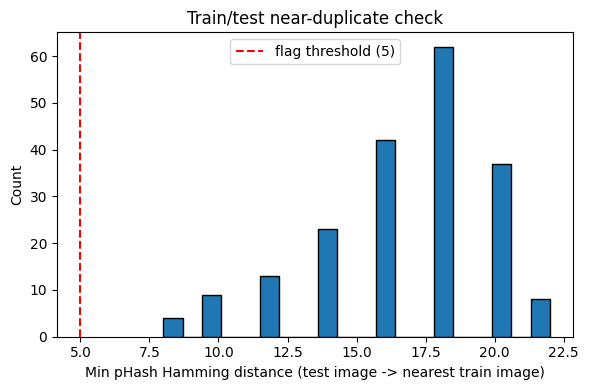


No near-duplicates flagged at this threshold — train/test overlap is not the likely explanation for high performance. (Still worth checking label balance, scanner/source confounds, and the SHAP sanity check in Section 15.)


In [3]:
import imagehash
from PIL import Image as PILImage


def compute_phashes(samples):
    hashes = {}
    for path, label in samples:
        h = imagehash.phash(PILImage.open(path).convert("L"))
        hashes[path] = (h, label)
    return hashes


train_hashes = compute_phashes(train_samples)
test_hashes = compute_phashes(test_samples)

DUP_THRESHOLD = 5  # Hamming distance on a 64-bit pHash; <=5 is a strong near-duplicate signal

dup_rows = []
for tpath, (th, tlabel) in test_hashes.items():
    best_dist, best_train, best_train_label = 999, None, None
    for trpath, (trh, trlabel) in train_hashes.items():
        d = th - trh
        if d < best_dist:
            best_dist, best_train, best_train_label = d, trpath, trlabel
    dup_rows.append({
        "test_path": tpath, "test_label": tlabel,
        "nearest_train_path": best_train, "nearest_train_label": best_train_label,
        "min_hamming_dist": best_dist,
        "flagged_near_duplicate": best_dist <= DUP_THRESHOLD,
    })

dup_df = pd.DataFrame(dup_rows)
dup_df.to_csv(TAB_DIR / "leakage_nearest_neighbor_hashes.csv", index=False)

n_flagged = dup_df["flagged_near_duplicate"].sum()
print(f"Test images with a near-duplicate in train (Hamming <= {DUP_THRESHOLD}): "
      f"{n_flagged} / {len(dup_df)}  ({100*n_flagged/len(dup_df):.1f}%)")
print(dup_df["min_hamming_dist"].describe())

plt.figure(figsize=(6, 4))
plt.hist(dup_df["min_hamming_dist"], bins=20, edgecolor="black")
plt.axvline(DUP_THRESHOLD, color="red", linestyle="--", label=f"flag threshold ({DUP_THRESHOLD})")
plt.xlabel("Min pHash Hamming distance (test image -> nearest train image)")
plt.ylabel("Count")
plt.title("Train/test near-duplicate check")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "leakage_hamming_distance_hist.png", dpi=300)
plt.show()

if n_flagged > 0:
    print("\n*** ACTION NEEDED: inspect the flagged rows below before trusting downstream "
          "metrics. If these are genuine near-duplicates (same case/frame in both splits), "
          "remove them from train or test and re-run the split. ***")
    display(dup_df[dup_df["flagged_near_duplicate"]].sort_values("min_hamming_dist").head(20))
else:
    print("\nNo near-duplicates flagged at this threshold — train/test overlap is not the "
          "likely explanation for high performance. (Still worth checking label balance, "
          "scanner/source confounds, and the SHAP sanity check in Section 15.)")

## 4. Radiomics feature extraction
**Option A (default, used below):** handcrafted first-order + GLCM texture features via
scikit-image. Works directly on the 2D grayscale image, no ROI mask required — appropriate
since images are already cropped to the ultrasound field of view.

**Option B (sketch at the bottom, commented):** true PyRadiomics extraction — IBSI-compliant,
what most Q1 radiomics papers cite by name. Requires a segmentation mask per image. If you have
(or can generate, e.g. via simple thresholding) a mask per image, switch to Option B for
stronger methodological standing in review.

In [4]:
import cv2
from skimage.feature import graycomatrix, graycoprops
from skimage.measure import shannon_entropy


def extract_radiomic_features(image_path: str) -> dict:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(image_path)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    feats = {}

    # ---- First-order statistics ----
    feats["mean"] = float(np.mean(img))
    feats["std"] = float(np.std(img))
    feats["variance"] = float(np.var(img))
    feats["skewness"] = float(pd.Series(img.ravel()).skew())
    feats["kurtosis"] = float(pd.Series(img.ravel()).kurtosis())
    feats["entropy"] = float(shannon_entropy(img))
    # NOTE: normalized (mean of squares), not raw sum — keeps the feature's scale
    # independent of IMG_SIZE, unlike a raw sum-of-squares "energy".
    feats["energy_mean_sq"] = float(np.mean(img.astype(np.float64) ** 2))
    feats["min"] = float(np.min(img))
    feats["max"] = float(np.max(img))
    p10, p25, p75, p90 = np.percentile(img, [10, 25, 75, 90])
    feats["p10"], feats["p25"], feats["p75"], feats["p90"] = map(float, (p10, p25, p75, p90))

    # ---- GLCM texture features (Haralick) ----
    img_q = (img.astype(np.float64) / 256.0 * 32).astype(np.uint8)  # quantize to reduce GLCM size/noise
    distances = [1, 3]
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(img_q, distances=distances, angles=angles,
                         levels=32, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        vals = graycoprops(glcm, prop)
        feats[f"glcm_{prop}_mean"] = float(np.mean(vals))
        feats[f"glcm_{prop}_std"] = float(np.std(vals))

    return feats


def build_feature_table(samples):
    rows = []
    for path, label in samples:
        feats = extract_radiomic_features(path)
        feats["label"] = label
        feats["filepath"] = path
        rows.append(feats)
    return pd.DataFrame(rows)


print("Extracting radiomic features (train)...")
radiomics_train_df = build_feature_table(train_samples)
print("Extracting radiomic features (test)...")
radiomics_test_df = build_feature_table(test_samples)
print(f"Train features: {radiomics_train_df.shape}, Test features: {radiomics_test_df.shape}")

Extracting radiomic features (train)...
Extracting radiomic features (test)...
Train features: (459, 27), Test features: (198, 27)


In [5]:
# ---------------------------------------------------------------
# OPTION B — true PyRadiomics (requires a mask per image), sketch:
# ---------------------------------------------------------------
# pip install pyradiomics --break-system-packages
#
# import SimpleITK as sitk
# from radiomics import featureextractor
# extractor = featureextractor.RadiomicsFeatureExtractor()
# extractor.enableAllFeatures()
#
# def extract_pyradiomics(image_path, mask_path):
#     image = sitk.ReadImage(image_path, sitk.sitkFloat32)
#     mask = sitk.ReadImage(mask_path, sitk.sitkUInt8)
#     result = extractor.execute(image, mask)
#     return {k: float(v) for k, v in result.items() if k.startswith("original_")}

## 5. Save intermediate features
These per-image feature tables are the raw material for manuscript supplementary tables and
for the feature-distribution / t-SNE figures below — save them **before** any scaling or
model-specific transformation.

In [6]:
radiomics_train_df.to_csv(TAB_DIR / "radiomics_features_train.csv", index=False)
radiomics_test_df.to_csv(TAB_DIR / "radiomics_features_test.csv", index=False)

feature_cols = [c for c in radiomics_train_df.columns if c not in ("label", "filepath")]
X_train = radiomics_train_df[feature_cols].values
y_train = radiomics_train_df["label"].values
X_test = radiomics_test_df[feature_cols].values
y_test = radiomics_test_df["label"].values

print(f"{len(feature_cols)} features: {feature_cols}")

25 features: ['mean', 'std', 'variance', 'skewness', 'kurtosis', 'entropy', 'energy_mean_sq', 'min', 'max', 'p10', 'p25', 'p75', 'p90', 'glcm_contrast_mean', 'glcm_contrast_std', 'glcm_dissimilarity_mean', 'glcm_dissimilarity_std', 'glcm_homogeneity_mean', 'glcm_homogeneity_std', 'glcm_energy_mean', 'glcm_energy_std', 'glcm_correlation_mean', 'glcm_correlation_std', 'glcm_ASM_mean', 'glcm_ASM_std']


## 6. Model zoo
Nine classical models spanning linear, distance-based, probabilistic, tree-ensemble, kernel,
and neural approaches — a broad classical-ML comparison table is itself a reasonable
contribution/robustness argument for a Q1 submission when you're not claiming a novel
architecture.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

model_zoo = {
    "logistic_regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10]},
    ),
    "knn": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 7, 9], "clf__weights": ["uniform", "distance"]},
    ),
    "naive_bayes": (
        GaussianNB(),
        {},  # no meaningful hyperparameters to grid-search; CV still gives an honest estimate
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, class_weight="balanced"),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 5, 10],
         "clf__min_samples_leaf": [1, 3, 5]},
    ),
    "extra_trees": (
        ExtraTreesClassifier(random_state=SEED, class_weight="balanced"),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10]},
    ),
    "gradient_boosting": (
        GradientBoostingClassifier(random_state=SEED),
        {"clf__n_estimators": [100, 200], "clf__max_depth": [2, 3], "clf__learning_rate": [0.05, 0.1]},
    ),
    "svm_rbf": (
        SVC(probability=True, random_state=SEED, class_weight="balanced"),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", "auto"]},
    ),
    "xgboost": (
        XGBClassifier(random_state=SEED, eval_metric="logloss", scale_pos_weight=pos_weight),
        {"clf__n_estimators": [100, 200], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1]},
    ),
    "mlp": (
        MLPClassifier(random_state=SEED, max_iter=1000, early_stopping=True),
        {"clf__hidden_layer_sizes": [(32,), (64, 32)], "clf__alpha": [1e-4, 1e-3]},
    ),
}
print(f"{len(model_zoo)} models: {list(model_zoo.keys())}")

9 models: ['logistic_regression', 'knn', 'naive_bayes', 'random_forest', 'extra_trees', 'gradient_boosting', 'svm_rbf', 'xgboost', 'mlp']


## 7. Nested cross-validation (leak-free) + final model fit
- `StandardScaler` lives **inside** the `Pipeline`, so it is refit on each training fold —
  no fold ever sees scaling statistics derived from data outside itself.
- **Nested CV** (outer fold = held-out estimate, inner fold = hyperparameter search),
  repeated `N_REPEATS` times with different fold splits, gives an unbiased, low-variance
  estimate of expected test performance — report this as your primary cross-validated metric.
- A **separate** final model is then tuned via CV on the *entire* training set and evaluated
  **once** on the untouched test set — this is your primary held-out result for the results
  table / ROC curve. The nested CV score above is the robustness check that supports it.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
import joblib

nested_scores = {}     # repeated nested-CV AUCs, for the "robustness" table/figure
final_models = {}      # final tuned pipelines, fit on full train
classical_results = {}  # predictions on the untouched test set

for name, (estimator, grid) in model_zoo.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])

    # ---- Nested CV: repeated for a stable, low-variance estimate ----
    rep_scores = []
    for rep in range(N_REPEATS):
        outer = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=SEED + rep)
        inner = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=SEED + rep)
        gs_inner = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1)
        scores = cross_val_score(gs_inner, X_train, y_train, cv=outer, scoring="roc_auc", n_jobs=-1)
        rep_scores.extend(scores.tolist())
    nested_scores[name] = rep_scores
    print(f"{name}: nested CV AUC = {np.mean(rep_scores):.4f} +/- {np.std(rep_scores):.4f} "
          f"(n={len(rep_scores)} folds across {N_REPEATS} repeats)")

    # ---- Final model: tune on the FULL training set, evaluate ONCE on test ----
    final_cv = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=SEED)
    gs_final = GridSearchCV(pipe, grid, cv=final_cv, scoring="roc_auc", n_jobs=-1)
    gs_final.fit(X_train, y_train)
    best_model = gs_final.best_estimator_
    final_models[name] = best_model
    print(f"  best params: {gs_final.best_params_}  |  train CV AUC: {gs_final.best_score_:.4f}")

    y_prob = best_model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    classical_results[name] = {"y_pred": y_pred, "y_prob": y_prob}

    joblib.dump(best_model, MODEL_DIR / f"{name}_final_pipeline.joblib")

nested_cv_df = pd.DataFrame({k: pd.Series(v) for k, v in nested_scores.items()})
nested_cv_df.to_csv(TAB_DIR / "nested_cv_auc_scores.csv", index=False)
print("\nNested CV AUC summary (report mean +/- std in Methods/Results):")
print(nested_cv_df.describe().loc[["mean", "std"]].round(4))

logistic_regression: nested CV AUC = 0.9817 +/- 0.0070 (n=15 folds across 3 repeats)
  best params: {'clf__C': 10}  |  train CV AUC: 0.9827
knn: nested CV AUC = 0.9698 +/- 0.0155 (n=15 folds across 3 repeats)
  best params: {'clf__n_neighbors': 7, 'clf__weights': 'distance'}  |  train CV AUC: 0.9710
naive_bayes: nested CV AUC = 0.9508 +/- 0.0179 (n=15 folds across 3 repeats)
  best params: {}  |  train CV AUC: 0.9519
random_forest: nested CV AUC = 0.9851 +/- 0.0097 (n=15 folds across 3 repeats)
  best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}  |  train CV AUC: 0.9856
extra_trees: nested CV AUC = 0.9855 +/- 0.0075 (n=15 folds across 3 repeats)
  best params: {'clf__max_depth': None, 'clf__n_estimators': 200}  |  train CV AUC: 0.9852
gradient_boosting: nested CV AUC = 0.9855 +/- 0.0113 (n=15 folds across 3 repeats)
  best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200}  |  train CV AUC: 0.9866
svm_rbf: nested

## 8. Held-out test metrics with bootstrap 95% CIs

In [9]:
from sklearn.metrics import (
    roc_auc_score, accuracy_score, confusion_matrix,
    precision_score, recall_score, f1_score, brier_score_loss, roc_curve,
)


def sensitivity_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return sens, spec


def compute_metrics(y_true, y_pred, y_prob):
    sens, spec = sensitivity_specificity(y_true, y_pred)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
        "sensitivity": sens,
        "specificity": spec,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "brier": brier_score_loss(y_true, y_prob),
    }


def bootstrap_ci(y_true, y_pred, y_prob, n_boot=N_BOOTSTRAP, seed=SEED, alpha=0.05):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    boot = {k: [] for k in ["accuracy", "auc", "sensitivity", "specificity", "precision", "f1", "brier"]}
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt, yp, ypr = y_true[idx], y_pred[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        m = compute_metrics(yt, yp, ypr)
        for k in boot:
            boot[k].append(m[k])
    ci = {}
    for k, vals in boot.items():
        vals = np.array(vals)
        lo, hi = np.percentile(vals, [100 * alpha / 2, 100 * (1 - alpha / 2)])
        ci[k] = (np.mean(vals), lo, hi)
    return ci


summary_rows = []
for name, res in classical_results.items():
    point = compute_metrics(y_test, res["y_pred"], res["y_prob"])
    ci = bootstrap_ci(y_test, res["y_pred"], res["y_prob"])
    row = {"model": name}
    for k in point:
        mean_b, lo, hi = ci[k]
        row[k] = point[k]
        row[f"{k}_ci_low"] = lo
        row[f"{k}_ci_high"] = hi
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("model").sort_values("auc", ascending=False)
summary_df.to_csv(TAB_DIR / "all_models_summary.csv")
summary_df

,accuracy,accuracy_ci_low,accuracy_ci_high,auc,auc_ci_low,auc_ci_high,sensitivity,sensitivity_ci_low,sensitivity_ci_high,specificity,...,specificity_ci_high,precision,precision_ci_low,precision_ci_high,f1,f1_ci_low,f1_ci_high,brier,brier_ci_low,brier_ci_high
model,,,,,,,,,,,,,,,,,,,,,
logistic_regression,0.969697,0.944444,0.989899,0.992755,0.982113,0.999076,0.959184,0.917412,0.990741,0.98,...,1.000000,0.979167,0.945055,1.000000,0.969072,0.941176,0.990385,0.033225,0.019239,0.051217
svm_rbf,0.964646,0.934343,0.989899,0.990000,0.970588,0.999592,0.979592,0.947917,1.000000,0.95,...,0.989583,0.950495,0.904762,0.989899,0.964824,0.934783,0.989476,0.027672,0.013187,0.045862
extra_trees,0.969697,0.944444,0.989899,0.989337,0.972605,0.998776,0.989796,0.966667,1.000000,0.95,...,0.989365,0.950980,0.905660,0.989796,0.970000,0.942295,0.990826,0.041163,0.028981,0.055961
xgboost,0.954545,0.924242,0.979798,0.989082,0.970780,0.998877,0.948980,0.903831,0.989583,0.96,...,0.990654,0.958763,0.915094,0.990385,0.953846,0.922065,0.980203,0.032442,0.014795,0.053738
gradient_boosting,0.969697,0.944444,0.989899,0.988776,0.972528,0.998982,0.969388,0.931818,1.000000,0.97,...,1.000000,0.969388,0.930676,1.000000,0.969388,0.943580,0.990101,0.029263,0.011190,0.051797
knn,0.964646,0.934343,0.989899,0.988520,0.972994,0.999287,0.948980,0.903846,0.989362,0.98,...,1.000000,0.978947,0.945055,1.000000,0.963731,0.934783,0.988767,0.033556,0.018016,0.052636
random_forest,0.964646,0.939394,0.989899,0.985612,0.962415,0.998467,0.989796,0.965907,1.000000,0.94,...,0.980952,0.941748,0.895238,0.981656,0.965174,0.937852,0.989011,0.037287,0.023845,0.054319
mlp,0.878788,0.833333,0.919192,0.970306,0.949065,0.986176,0.918367,0.861373,0.968085,0.84,...,0.908186,0.849057,0.778945,0.914286,0.882353,0.834222,0.925234,0.076521,0.058283,0.097183
naive_bayes,0.898990,0.858586,0.939394,0.966327,0.942386,0.984657,0.908163,0.848478,0.961548,0.89,...,0.945660,0.890000,0.825230,0.947368,0.898990,0.851064,0.939535,0.090364,0.053708,0.128962


## 9. Pairwise statistical comparison (Holm–Bonferroni corrected)
With 9 models there are 36 pairwise comparisons per test (McNemar + bootstrap AUC-difference =
72 tests total) — correction matters a lot more here than with 3 models. Both families are
corrected with the Holm–Bonferroni method — report `p_holm` and `significant_holm` in the
manuscript, not the raw p-values.

In [10]:
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

names = list(classical_results.keys())
mcnemar_rows, aucdiff_rows = [], []

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        na, nb = names[i], names[j]
        pred_a, pred_b = classical_results[na]["y_pred"], classical_results[nb]["y_pred"]
        correct_a, correct_b = (pred_a == y_test), (pred_b == y_test)
        n11 = np.sum(correct_a & correct_b)
        n10 = np.sum(correct_a & ~correct_b)
        n01 = np.sum(~correct_a & correct_b)
        n00 = np.sum(~correct_a & ~correct_b)
        result = mcnemar([[n11, n10], [n01, n00]], exact=True)
        mcnemar_rows.append({"model_a": na, "model_b": nb, "statistic": result.statistic, "p_value": result.pvalue})

        prob_a, prob_b = classical_results[na]["y_prob"], classical_results[nb]["y_prob"]
        rng = np.random.RandomState(SEED)
        n = len(y_test)
        diffs = []
        for _ in range(N_BOOTSTRAP):
            idx = rng.randint(0, n, n)
            yt = y_test[idx]
            if len(np.unique(yt)) < 2:
                continue
            diffs.append(roc_auc_score(yt, prob_a[idx]) - roc_auc_score(yt, prob_b[idx]))
        diffs = np.array(diffs)
        obs_diff = roc_auc_score(y_test, prob_a) - roc_auc_score(y_test, prob_b)
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        p_value = min(2 * min((diffs > 0).mean(), (diffs < 0).mean()), 1.0)
        aucdiff_rows.append({"model_a": na, "model_b": nb, "auc_diff": obs_diff,
                              "ci_low": lo, "ci_high": hi, "p_value": p_value})

mcnemar_df = pd.DataFrame(mcnemar_rows)
aucdiff_df = pd.DataFrame(aucdiff_rows)

for df in (mcnemar_df, aucdiff_df):
    rej, p_holm, _, _ = multipletests(df["p_value"].values, alpha=0.05, method="holm")
    df["p_holm"] = p_holm
    df["significant_holm"] = rej

mcnemar_df.to_csv(TAB_DIR / "mcnemar_pairwise.csv", index=False)
aucdiff_df.to_csv(TAB_DIR / "aucdiff_pairwise.csv", index=False)

print(f"McNemar: {mcnemar_df['significant_holm'].sum()} / {len(mcnemar_df)} pairs significant after Holm correction")
print(f"AUC-diff: {aucdiff_df['significant_holm'].sum()} / {len(aucdiff_df)} pairs significant after Holm correction")
aucdiff_df.sort_values("p_holm").head(10)

McNemar: 8 / 36 pairs significant after Holm correction
AUC-diff: 4 / 36 pairs significant after Holm correction


,model_a,model_b,auc_diff,ci_low,ci_high,p_value,p_holm,significant_holm
1,logistic_regression,naive_bayes,0.026429,0.010380,0.046939,0.000,0.000,True
7,logistic_regression,mlp,0.022449,0.010110,0.039672,0.000,0.000,True
8,knn,naive_bayes,0.022194,0.007971,0.039811,0.000,0.000,True
29,extra_trees,mlp,0.019031,0.005109,0.036054,0.001,0.033,True
32,gradient_boosting,mlp,0.018469,0.004603,0.036327,0.004,0.128,False
16,naive_bayes,extra_trees,-0.023010,-0.043893,-0.004606,0.008,0.248,False
34,svm_rbf,mlp,0.019694,0.004079,0.036629,0.010,0.300,False
14,knn,mlp,0.018214,0.004043,0.035953,0.010,0.300,False
17,naive_bayes,gradient_boosting,-0.022449,-0.042403,-0.004710,0.011,0.308,False
35,xgboost,mlp,0.018776,0.003979,0.036426,0.012,0.324,False


## 10. ROC curve overlay

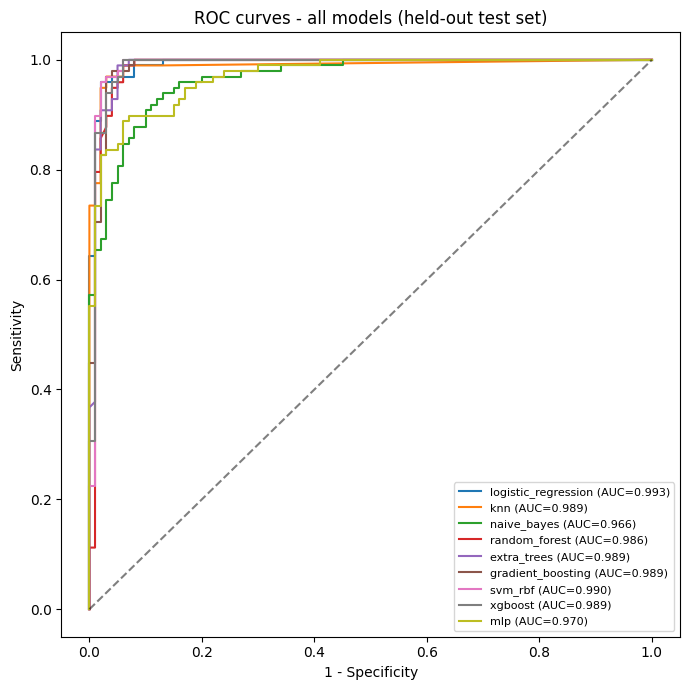

In [11]:
plt.figure(figsize=(7, 7))
for name, res in classical_results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    auc = roc_auc_score(y_test, res["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("1 - Specificity")
plt.ylabel("Sensitivity")
plt.title("ROC curves - all models (held-out test set)")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_overlay_all_models.png", dpi=300)
plt.show()

## 11. Calibration curves

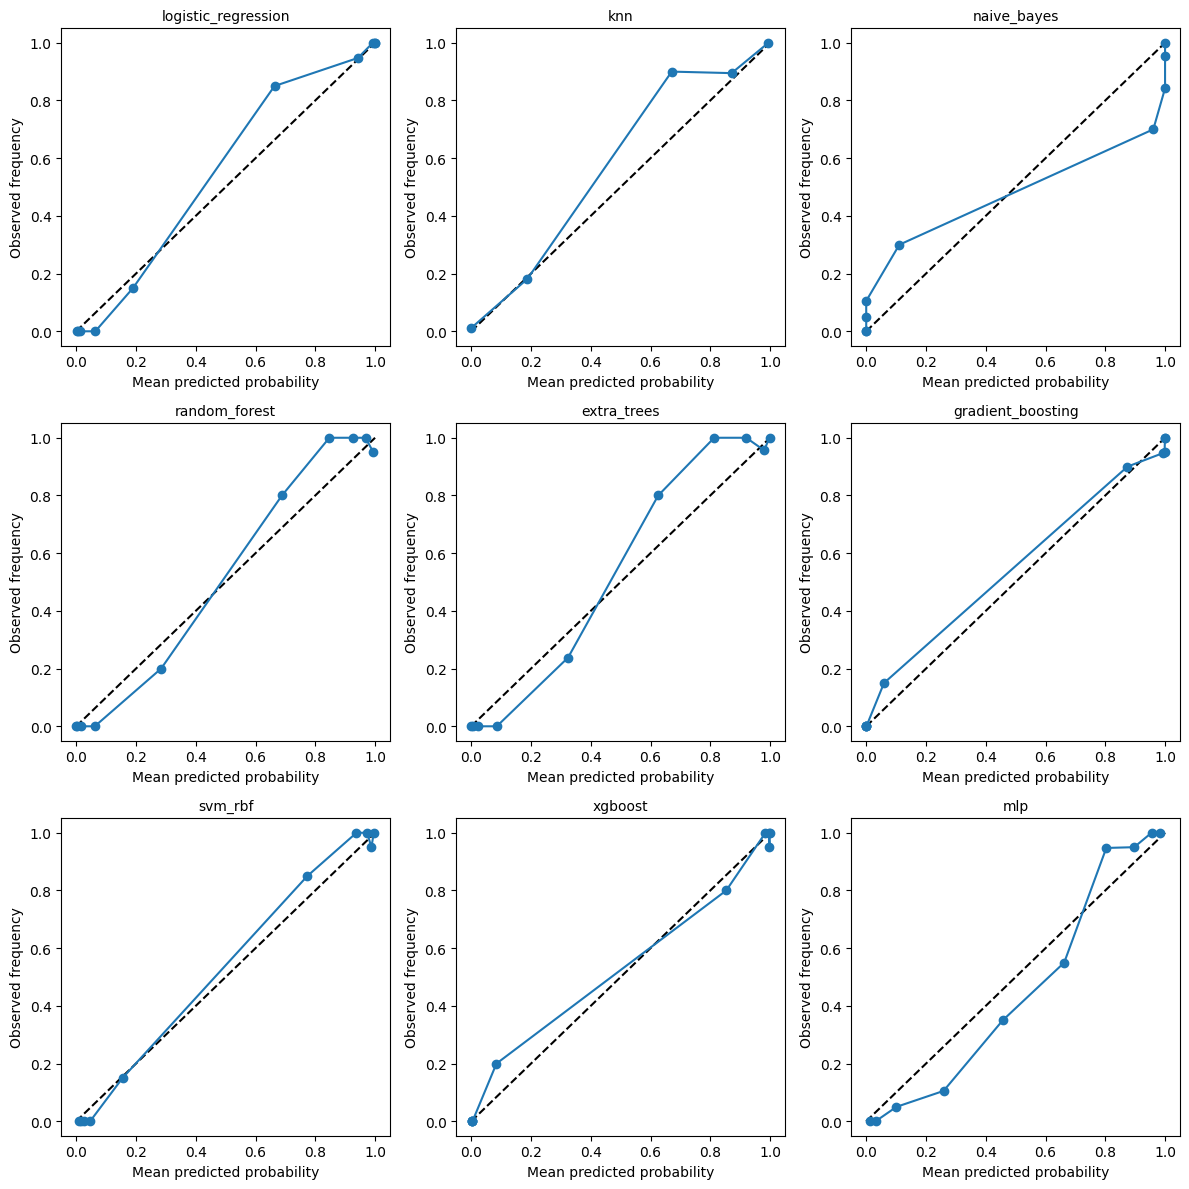

In [12]:
from sklearn.calibration import calibration_curve

n_models = len(classical_results)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (name, res) in zip(axes.ravel(), classical_results.items()):
    frac_pos, mean_pred = calibration_curve(y_test, res["y_prob"], n_bins=10, strategy="quantile")
    ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
    ax.plot(mean_pred, frac_pos, "o-", label=name)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed frequency")
    ax.set_title(name, fontsize=10)
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_all_models.png", dpi=300)
plt.show()

## 12. Confusion matrices

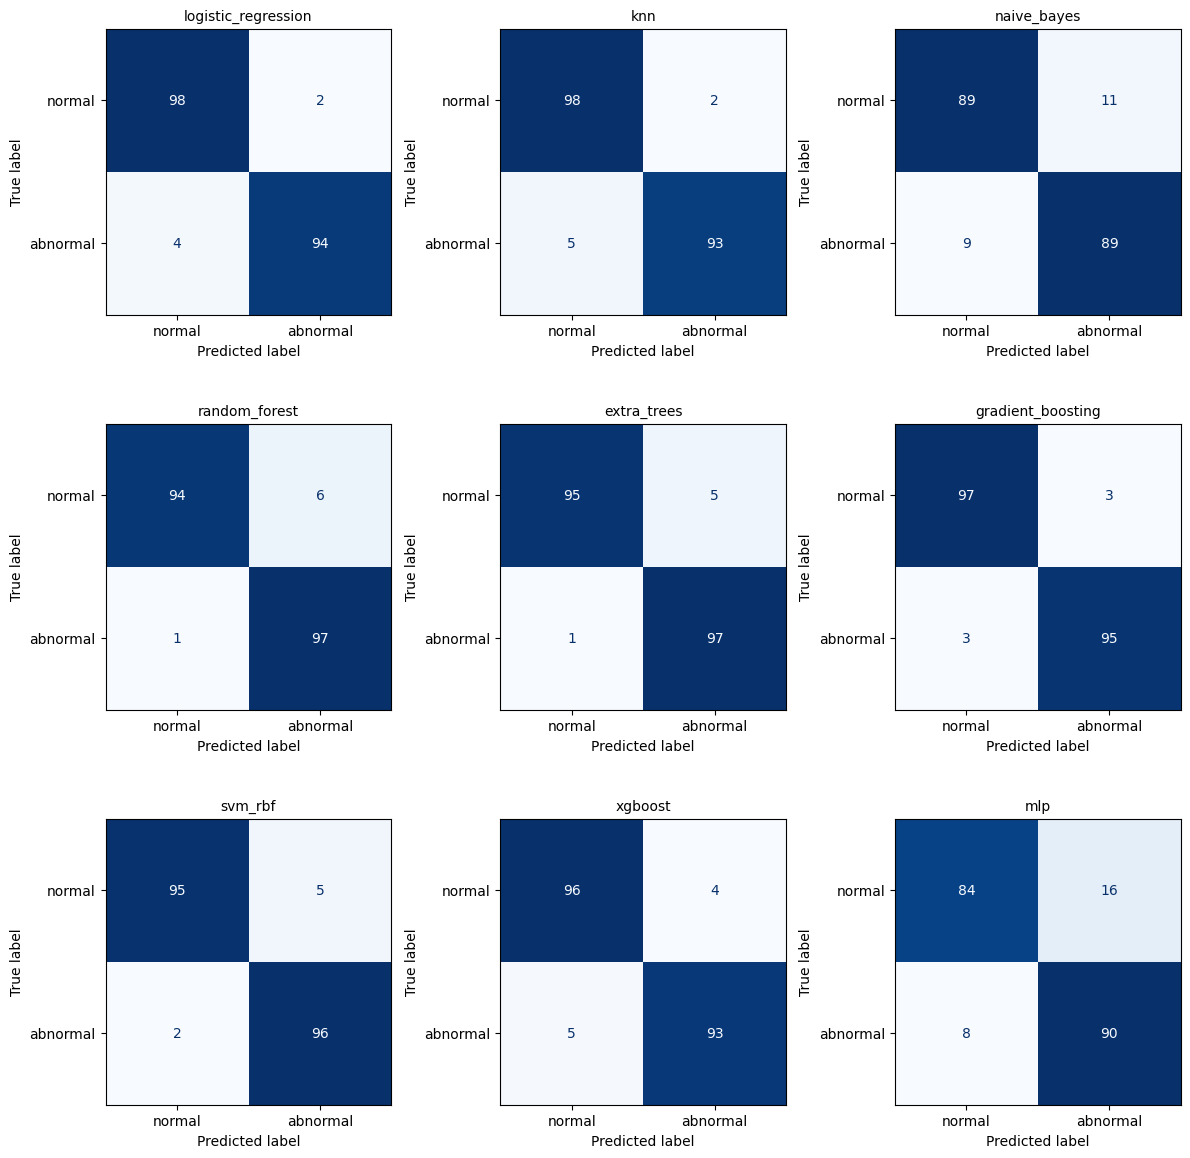

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (name, res) in zip(axes.ravel(), classical_results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, res["y_pred"], display_labels=CLASS_NAMES, ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name, fontsize=10)
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices_all_models.png", dpi=300)
plt.show()

## 13. t-SNE of the radiomics feature space
A 2D projection of the (scaled) feature space, colored by class — a standard "does the
feature space separate the classes" figure for the paper. Scaler is fit on train only and
applied to both splits, consistent with the modeling pipeline above.

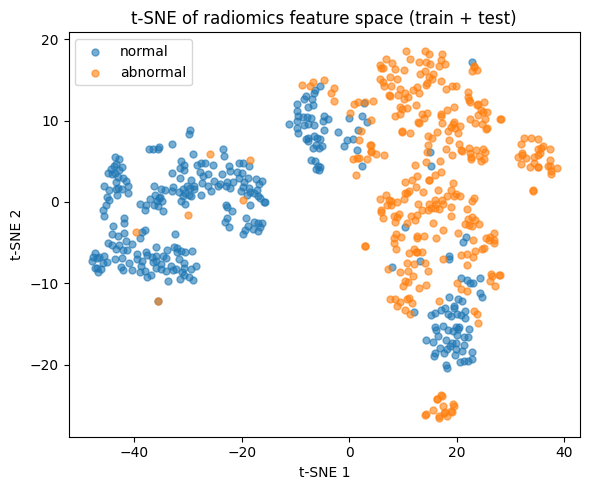

In [14]:
from sklearn.manifold import TSNE

scaler_viz = StandardScaler().fit(X_train)
X_all = np.vstack([scaler_viz.transform(X_train), scaler_viz.transform(X_test)])
y_all = np.concatenate([y_train, y_test])
split_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))

perplexity = max(5, min(30, len(X_all) // 4))
tsne = TSNE(n_components=2, random_state=SEED, perplexity=perplexity, init="pca")
embedding = tsne.fit_transform(X_all)

plt.figure(figsize=(6, 5))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    m = y_all == cls_idx
    plt.scatter(embedding[m, 0], embedding[m, 1], label=cls_name, alpha=0.6, s=25)
plt.legend()
plt.title("t-SNE of radiomics feature space (train + test)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.savefig(FIG_DIR / "tsne_by_class.png", dpi=300)
plt.show()

pd.DataFrame({
    "tsne_1": embedding[:, 0], "tsne_2": embedding[:, 1],
    "label": y_all, "split": split_all,
}).to_csv(TAB_DIR / "tsne_embedding.csv", index=False)

# NOTE: t-SNE layout is stochastic and sensitive to `perplexity` — for the paper, report
# the perplexity used and consider running a couple of seeds to confirm the class
# separation you show isn't an artifact of one particular embedding.

## 14. SHAP interpretability
Tree-based models (RF, Extra Trees, Gradient Boosting, XGBoost) get exact, fast SHAP values via
`TreeExplainer`. Logistic Regression gets `LinearExplainer`. This is the "which features drive
the decision, and clinically why" figure for the discussion section.

KNN / Naive Bayes / SVM / MLP would need the slower, model-agnostic `KernelExplainer` — not run
by default here (can take minutes even on a modest test set); a commented template is included
if you decide you need it for one of them.

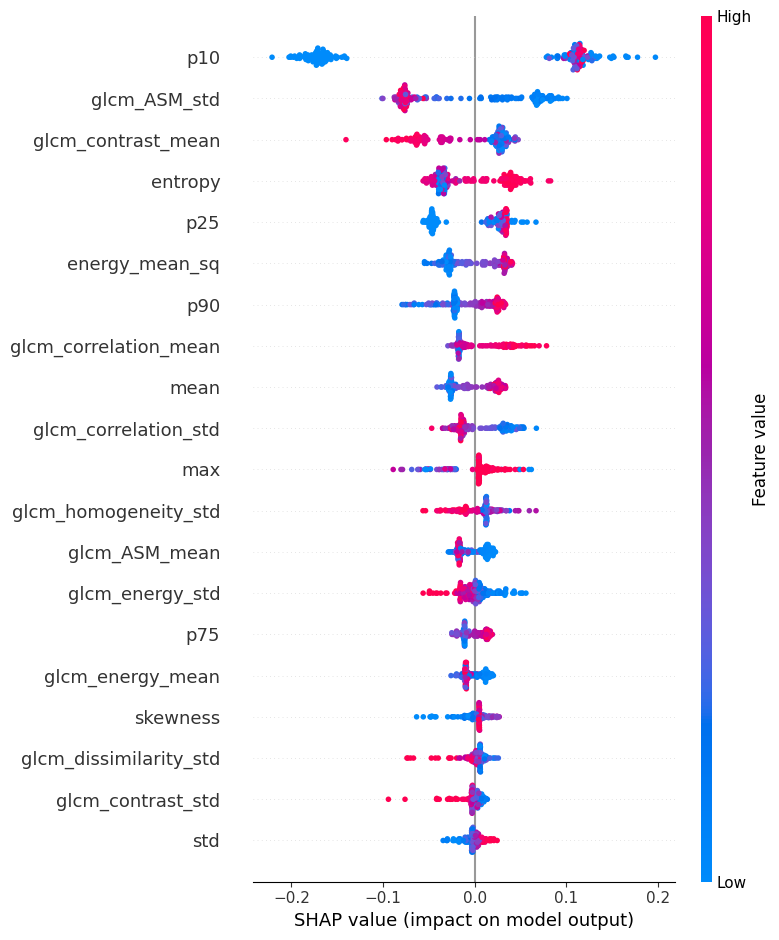


random_forest - top 8 features by mean |SHAP|:
p10                      0.139730
glcm_ASM_std             0.066090
glcm_contrast_mean       0.039130
entropy                  0.035942
p25                      0.035111
energy_mean_sq           0.027903
p90                      0.024638
glcm_correlation_mean    0.023601
dtype: float64


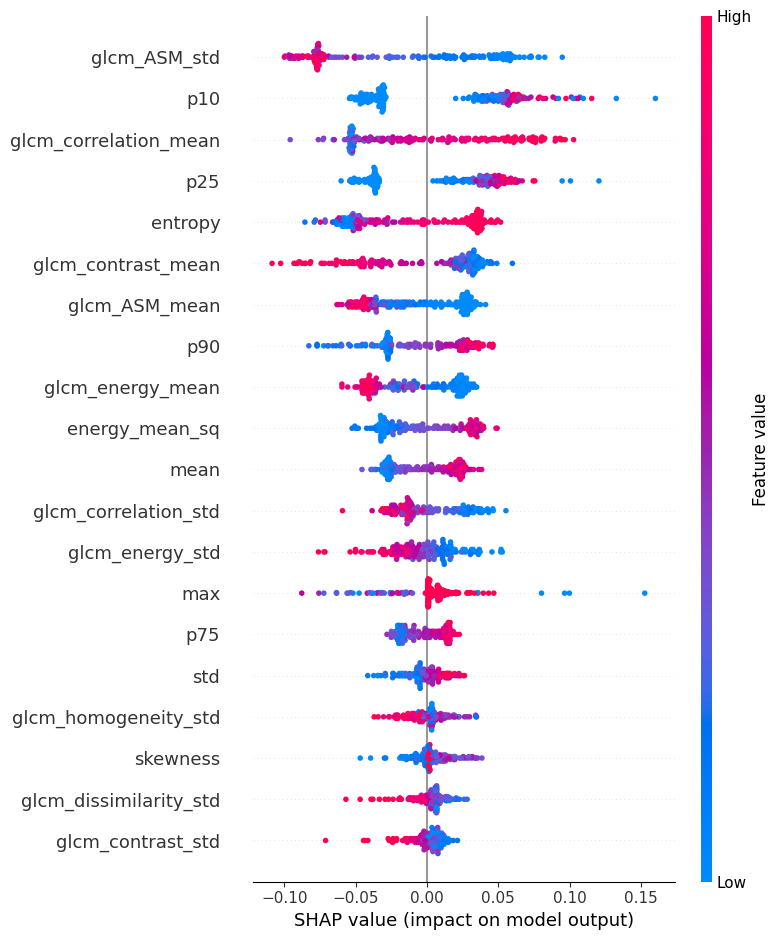


extra_trees - top 8 features by mean |SHAP|:
glcm_ASM_std             0.055587
p10                      0.049300
glcm_correlation_mean    0.045251
p25                      0.041649
entropy                  0.039223
glcm_contrast_mean       0.037192
glcm_ASM_mean            0.029277
p90                      0.027738
dtype: float64


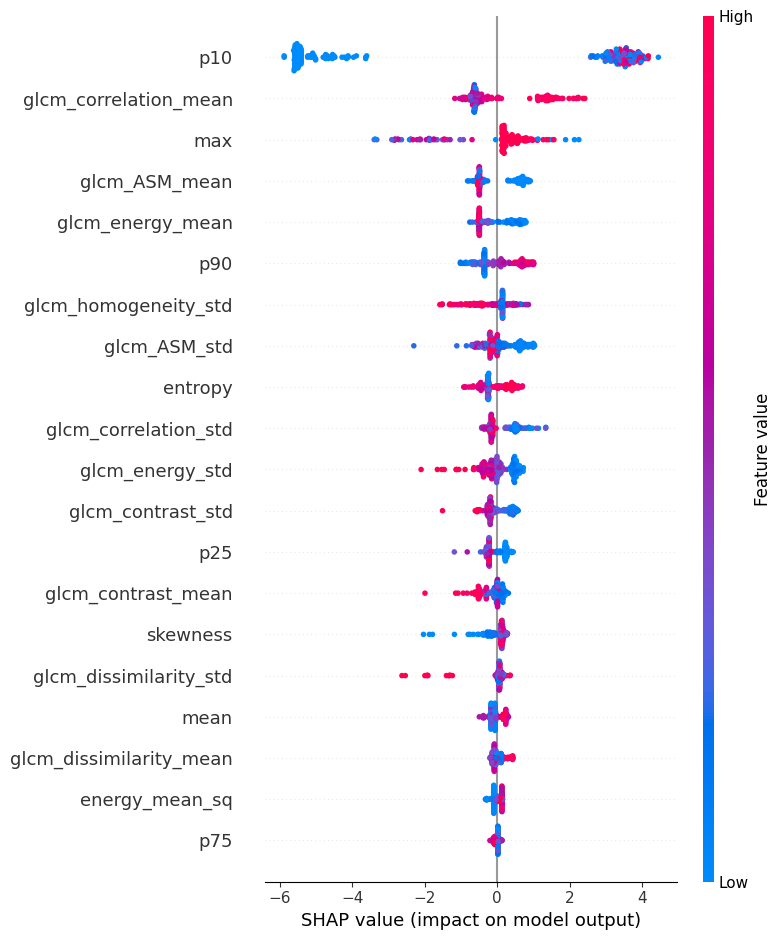


gradient_boosting - top 8 features by mean |SHAP|:
p10                      4.197968
glcm_correlation_mean    0.837524
max                      0.756235
glcm_ASM_mean            0.581522
glcm_energy_mean         0.492908
p90                      0.466608
glcm_homogeneity_std     0.388425
glcm_ASM_std             0.381503
dtype: float64


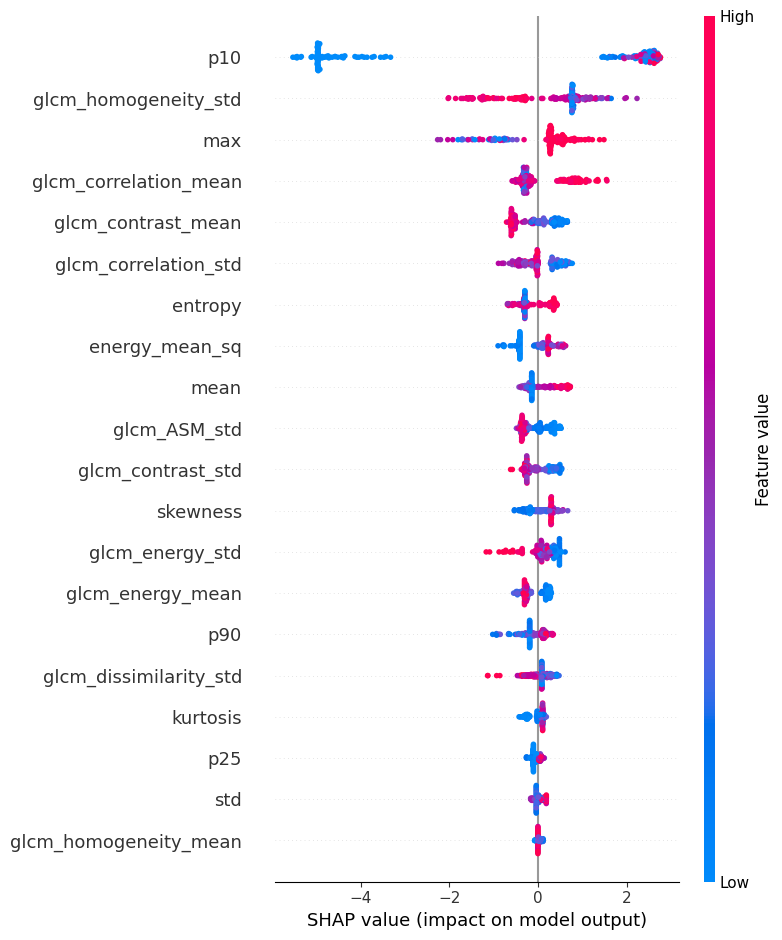


xgboost - top 8 features by mean |SHAP|:
p10                      3.398797
glcm_homogeneity_std     0.871644
max                      0.595212
glcm_correlation_mean    0.465873
glcm_contrast_mean       0.407013
glcm_correlation_std     0.330658
entropy                  0.325023
energy_mean_sq           0.313258
dtype: float32


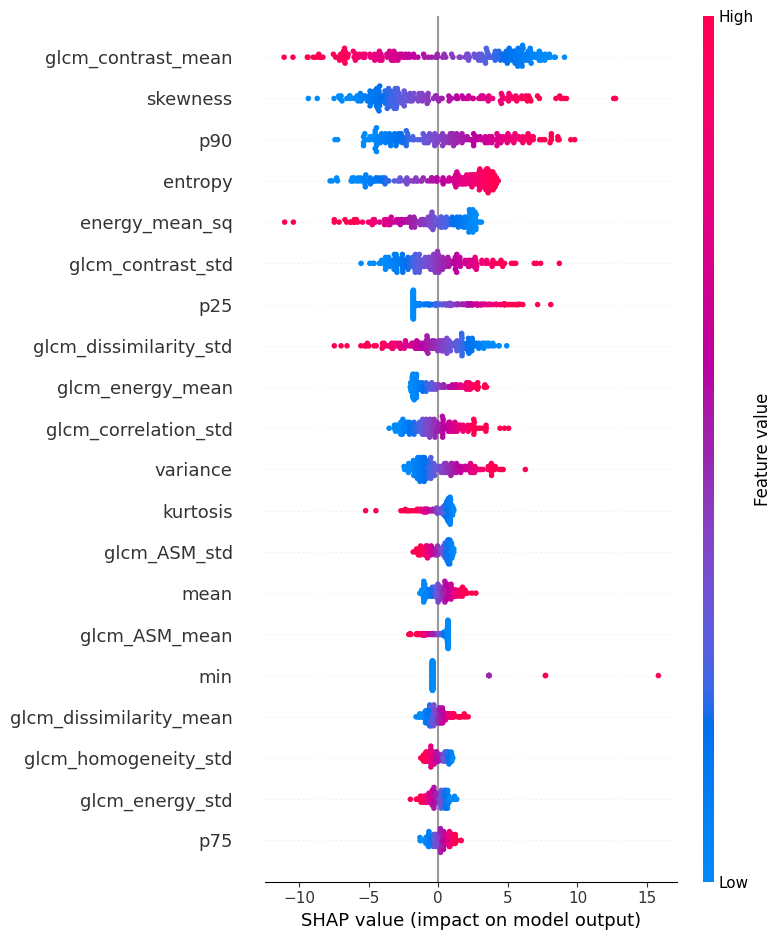


logistic_regression - top 8 features by mean |SHAP|:
glcm_contrast_mean        4.961414
skewness                  3.912885
p90                       3.392937
entropy                   3.072174
energy_mean_sq            2.181595
glcm_contrast_std         2.102226
p25                       2.030558
glcm_dissimilarity_std    1.930733
dtype: float64


In [15]:
import shap

shap_summary = {}
tree_models = ["random_forest", "extra_trees", "gradient_boosting", "xgboost"]
linear_models = ["logistic_regression"]

for name in tree_models + linear_models:
    if name not in final_models:
        continue
    pipe = final_models[name]
    clf = pipe.named_steps["clf"]
    X_test_scaled = pipe.named_steps["scaler"].transform(X_test)

    if name in tree_models:
        explainer = shap.TreeExplainer(clf)
        shap_values = explainer.shap_values(X_test_scaled)
        if isinstance(shap_values, list):
            sv = shap_values[1]
        elif np.asarray(shap_values).ndim == 3:
            sv = shap_values[:, :, 1]
        else:
            sv = shap_values
    else:
        X_train_scaled = pipe.named_steps["scaler"].transform(X_train)
        explainer = shap.LinearExplainer(clf, X_train_scaled)
        sv = explainer.shap_values(X_test_scaled)

    plt.figure()
    shap.summary_plot(sv, X_test_scaled, feature_names=feature_cols, show=False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"shap_summary_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

    np.save(TAB_DIR / f"shap_values_{name}.npy", sv)

    mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=feature_cols).sort_values(ascending=False)
    mean_abs_shap.to_csv(TAB_DIR / f"shap_feature_importance_{name}.csv", header=["mean_abs_shap"])
    shap_summary[name] = mean_abs_shap

    print(f"\n{name} - top 8 features by mean |SHAP|:")
    print(mean_abs_shap.head(8))

# ---------------------------------------------------------------
# Template for KNN / Naive Bayes / SVM / MLP via KernelExplainer, if needed:
# ---------------------------------------------------------------
# background = shap.sample(X_train_scaled, 50, random_state=SEED)
# kernel_explainer = shap.KernelExplainer(final_models["svm_rbf"].predict_proba, background)
# kernel_shap_values = kernel_explainer.shap_values(X_test_scaled, nsamples=100)

## 15. SHAP sanity check — is the top feature plausible or an artifact?
Ranking features by mean |SHAP| tells you what the model uses, not whether that's a *genuine*
signal. This cell plots the raw (unscaled) distribution of the top-ranked features by class —
a smooth, physically-plausible-looking shift (e.g. in a texture/entropy feature) supports a
real signal; a feature like `mean` or `p90` cleanly separating the classes with no overlap is
worth checking against acquisition metadata (scanner, site, preprocessing) before treating it
as a clinical finding, since it can also indicate a shortcut rather than genuine anatomy.

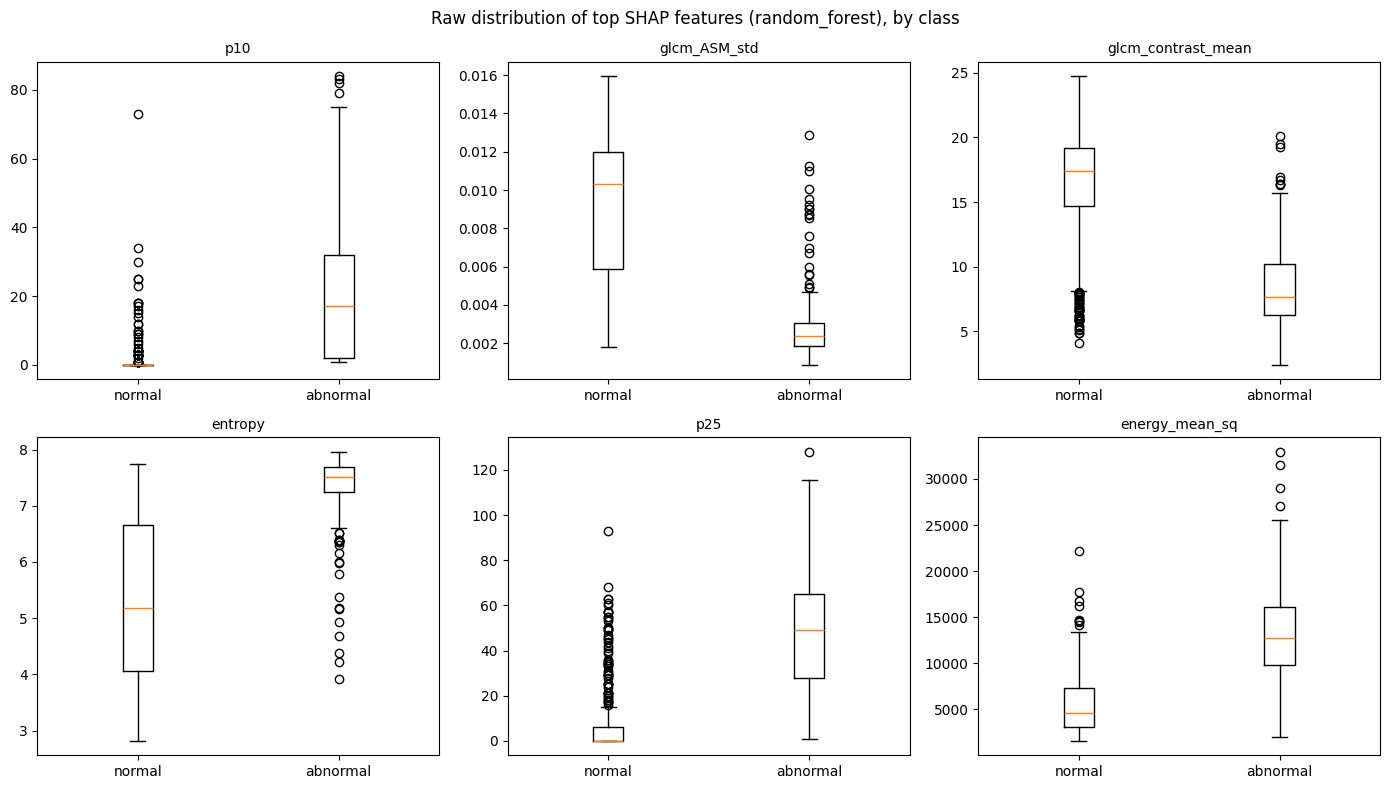

Ask for each panel: does the separation look like a real texture/intensity signal, or a near-total non-overlap that would be too easy for this task? The latter is worth cross-checking against scanner/site/acquisition metadata before treating it as a genuine radiomic finding.


In [16]:
reference_model = "random_forest" if "random_forest" in shap_summary else list(shap_summary.keys())[0]
top_features = shap_summary[reference_model].head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
combined_df = pd.concat([
    radiomics_train_df.assign(split="train"),
    radiomics_test_df.assign(split="test"),
])
for ax, feat in zip(axes.ravel(), top_features):
    data_normal = combined_df.loc[combined_df["label"] == 0, feat]
    data_abnormal = combined_df.loc[combined_df["label"] == 1, feat]
    ax.boxplot([data_normal, data_abnormal], labels=CLASS_NAMES)
    ax.set_title(feat, fontsize=10)
plt.suptitle(f"Raw distribution of top SHAP features ({reference_model}), by class")
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_top_feature_sanity_check.png", dpi=300)
plt.show()

print("Ask for each panel: does the separation look like a real texture/intensity signal, or "
      "a near-total non-overlap that would be too easy for this task? The latter is worth "
      "cross-checking against scanner/site/acquisition metadata before treating it as a "
      "genuine radiomic finding.")

## 16. Patient-level leakage check
Near-duplicate hashing (Section 3) only catches identical/near-identical frames. It will
**not** catch the case where the *same patient* contributed different images to both train
and test — a common, easy-to-miss leakage source in medical-imaging splits. This cell tries
to infer a patient/subject ID from each filename and checks for overlap between splits.

**Fixed in this version:** the original regex stripped the trailing sequence number as if it
were a frame/slice suffix, which — for this dataset's `<Label>_<number>` filenames — collapsed
every image down to just two "patients" (`Abnormal`, `Normal`), producing a false leakage
warning that was really just comparing class labels against themselves. The number is now kept
as part of the ID.

**IMPORTANT:** this still assumes each `<Label>_<number>` is one unique patient/image with no
repeats. If your actual acquisition process captured multiple images per patient (extra frames,
augmented copies, follow-up scans) under filenames that don't obviously encode that, filename
parsing alone cannot detect it — you'd need to cross-reference the original source/DICOM
metadata or a patient log to be certain. Open `patient_id_split_check.csv` afterward and
manually confirm the inferred IDs look right for your actual filename convention before
trusting the "no overlap" result.

In [17]:
import re

def extract_patient_id(filepath: str) -> str:
    """
    Patient/subject ID extraction for filenames of the form
    '<Label>_<number>.<ext>' (e.g. 'Abnormal_0012.jpg', 'Normal_0186.png').

    IMPORTANT FIX (previous version): the old regex stripped the trailing
    '_<number>' as if it were a frame/slice/augmentation suffix. Since every
    filename in this dataset is JUST '<Label>_<number>', that stripped the
    *entire* identifying number, collapsing all abnormal images to the single
    ID "Abnormal" and all normal images to "Normal" -- which is why the old
    check reported "2 patient IDs total" with a false-positive overlap
    warning. It was comparing class labels, not patients.

    This version keeps the number as part of the ID (Label + number = ID),
    which is the correct default when filenames have no separate frame/slice/
    augmentation suffix beyond the single sequence number.

    >>> If your numbering scheme has multiple images per patient (e.g. several
    >>> frames or augmented copies sharing one patient number, distinguished by
    >>> an extra suffix like '_a'/'_b' or '_frame2'), EDIT this regex to strip
    >>> only that extra suffix -- do not strip the primary sequence number. <<<
    """
    stem = Path(filepath).stem
    # Strip ONLY an explicit frame/slice/augmentation suffix appended AFTER
    # the main Label_number, e.g. 'Abnormal_0012_frame2' -> 'Abnormal_0012'.
    # Does NOT touch a bare trailing number, since that IS the patient ID here.
    pid = re.sub(r'[_\-](frame|slice|aug|copy)[\-_]?\d*$', '', stem, flags=re.IGNORECASE)
    return pid if pid else stem


train_patient_ids = {extract_patient_id(p) for p, _ in train_samples}
test_patient_ids  = {extract_patient_id(p) for p, _ in test_samples}
overlap = train_patient_ids & test_patient_ids

print(f"Inferred unique patient IDs — train: {len(train_patient_ids)}, test: {len(test_patient_ids)}")
print(f"Overlapping inferred patient IDs between train/test: {len(overlap)}")
if overlap:
    print("\n!!! WARNING: possible patient-level leakage. Overlapping IDs (up to 20 shown):")
    print(sorted(overlap)[:20])
else:
    print("No overlapping inferred patient IDs — consistent with a patient-independent split.")
    print("Still manually spot-check patient_id_split_check.csv against your real ID scheme.")

id_check_df = pd.DataFrame({
    "filepath": [p for p, _ in train_samples] + [p for p, _ in test_samples],
    "split": ["train"] * len(train_samples) + ["test"] * len(test_samples),
    "inferred_patient_id": (
        [extract_patient_id(p) for p, _ in train_samples]
        + [extract_patient_id(p) for p, _ in test_samples]
    ),
})
id_check_df.to_csv(TAB_DIR / "patient_id_split_check.csv", index=False)

# Sanity check: with this fix, unique ID count should be close to (or equal to)
# the total image count, unless your data genuinely has repeat patients.
n_total = len(train_samples) + len(test_samples)
n_unique = len(train_patient_ids | test_patient_ids)
print(f"\nSanity check: {n_unique} unique inferred IDs out of {n_total} total images.")
if n_unique == n_total:
    print("Every image got a distinct ID -- if your data truly has multiple images per")
    print("patient, this means the regex isn't catching that pattern; edit it above.")


Inferred unique patient IDs — train: 459, test: 198
Overlapping inferred patient IDs between train/test: 0
No overlapping inferred patient IDs — consistent with a patient-independent split.
Still manually spot-check patient_id_split_check.csv against your real ID scheme.

Sanity check: 657 unique inferred IDs out of 657 total images.
Every image got a distinct ID -- if your data truly has multiple images per
patient, this means the regex isn't catching that pattern; edit it above.


## 17. Feature-level shortcut check (single-feature AUC)
SHAP tells you what the model *uses*, but a single first-order intensity feature (e.g.
`p10`, `mean`) achieving near-ceiling separation **on its own** is a classic shortcut-learning
signature — more consistent with a scanner/brightness/preprocessing artifact than a genuine
radiomic finding. This cell scores every feature *alone* (no model) against the held-out
test labels. Flag anything above the threshold and cross-check it against acquisition
metadata (scanner, site, operator, preprocessing pipeline) before reporting it as a
clinical finding in Discussion.


In [18]:
from sklearn.metrics import roc_auc_score

HIGH_AUC_THRESHOLD = 0.90  # single-feature AUC above this is worth scrutinizing

feat_check_rows = []
for feat in feature_cols:
    vals = radiomics_test_df[feat].values
    try:
        auc = roc_auc_score(y_test, vals)
        auc = max(auc, 1 - auc)  # direction-agnostic (feature could correlate either way)
    except Exception:
        auc = np.nan
    feat_check_rows.append({"feature": feat, "single_feature_auc_test": auc})

feat_check_df = pd.DataFrame(feat_check_rows).sort_values(
    "single_feature_auc_test", ascending=False
)
feat_check_df.to_csv(TAB_DIR / "single_feature_auc_shortcut_check.csv", index=False)

print("Top single features by AUC alone (held-out test set, direction-agnostic):")
print(feat_check_df.head(10).to_string(index=False))

flagged = feat_check_df[feat_check_df["single_feature_auc_test"] > HIGH_AUC_THRESHOLD]
if len(flagged):
    print(f"\n!!! {len(flagged)} feature(s) exceed single-feature AUC={HIGH_AUC_THRESHOLD} alone:")
    print(flagged.to_string(index=False))
    print(
        "\nThese are candidates for a shortcut/confound rather than genuine radiomic signal — "
        "cross-check against scanner/site/acquisition metadata (see Section 15 SHAP sanity "
        "check for the corresponding raw-distribution plots) before including as a clinical "
        "finding."
    )
else:
    print(f"\nNo single feature exceeds AUC={HIGH_AUC_THRESHOLD} alone — no single obvious shortcut feature.")


Top single features by AUC alone (held-out test set, direction-agnostic):
              feature  single_feature_auc_test
                  p10                 0.948316
         glcm_ASM_std                 0.942143
              entropy                 0.936735
                  p25                 0.927959
                 mean                 0.926837
glcm_correlation_mean                 0.925204
        glcm_ASM_mean                 0.920204
     glcm_energy_mean                 0.919898
       energy_mean_sq                 0.905102
                  p75                 0.890663

!!! 9 feature(s) exceed single-feature AUC=0.9 alone:
              feature  single_feature_auc_test
                  p10                 0.948316
         glcm_ASM_std                 0.942143
              entropy                 0.936735
                  p25                 0.927959
                 mean                 0.926837
glcm_correlation_mean                 0.925204
        glcm_ASM_mean    

## 18. Per-model t-SNE maps — decision agreement across the model zoo
Uses the single t-SNE embedding already computed in Section 13 (fit once on the scaled
train+test feature space, so it's comparable across models) and overlays each model's
held-out test predictions. Correct predictions are shown by true class (circle = normal,
triangle = abnormal); misclassifications are marked with a red X. Panels with misclassified
points scattered *inside* a class cluster (rather than at cluster boundaries) are worth a
closer look — that pattern is more consistent with a mislabeled/ambiguous case than with a
model-driven error at a genuine decision boundary. This is a strong supplementary figure for
a Q1 submission: one embedding, all models, transparent about where each one struggles.


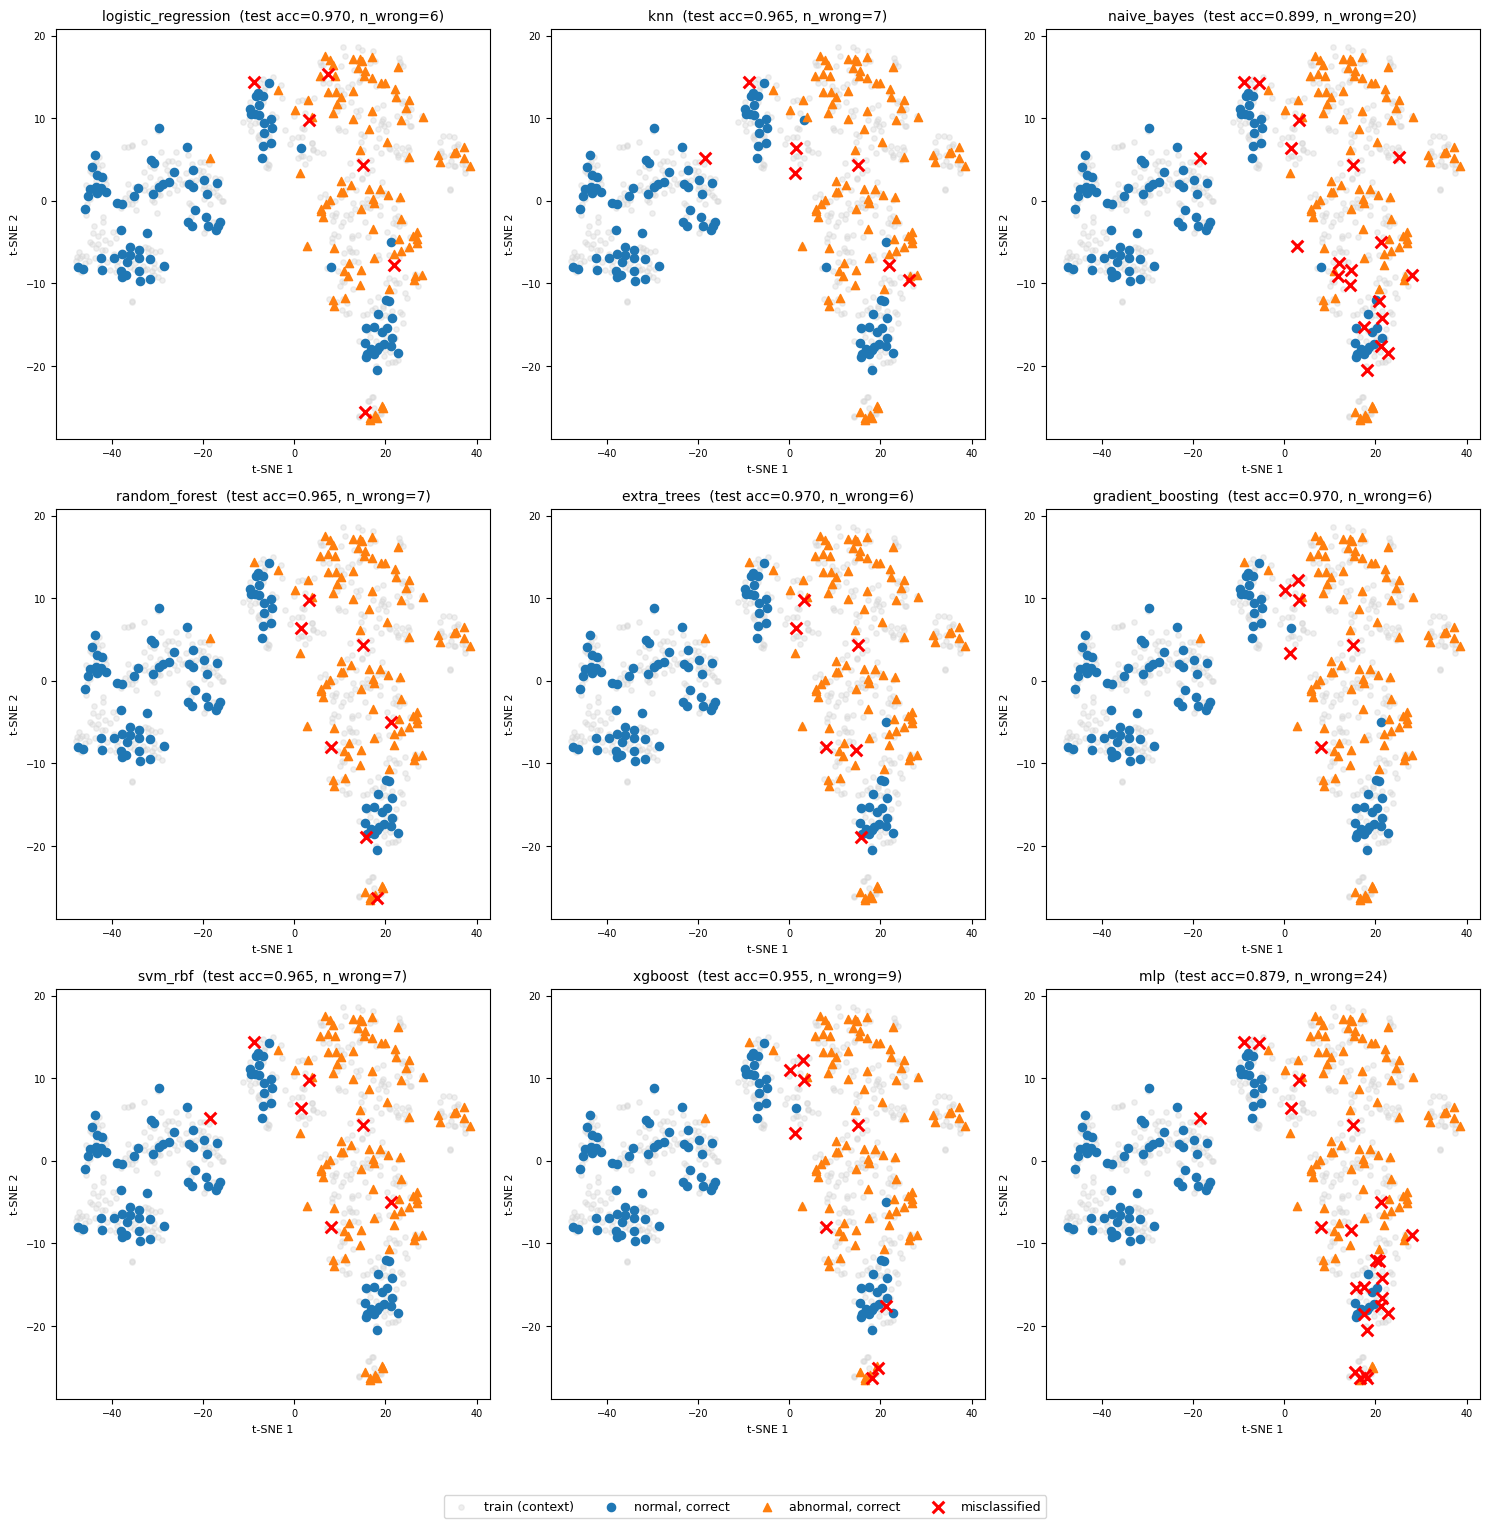

Test samples misclassified by ALL 9 models: 1 / 198
Saved to consistently_misclassified_test_samples.csv — worth a manual image review; consistent cross-model errors are more likely genuine hard/ambiguous cases than model-specific noise.


In [19]:
test_mask = split_all == "test"
embedding_test = embedding[test_mask]
embedding_train = embedding[~test_mask]

n_models = len(classical_results)
ncols = 3
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, (name, res) in zip(axes, classical_results.items()):
    y_pred = res["y_pred"]
    correct = (y_pred == y_test)

    ax.scatter(embedding_train[:, 0], embedding_train[:, 1],
               c="lightgray", s=15, alpha=0.35, label="train (context)")

    m_norm_ok = correct & (y_test == 0)
    m_abn_ok = correct & (y_test == 1)
    m_wrong = ~correct

    ax.scatter(embedding_test[m_norm_ok, 0], embedding_test[m_norm_ok, 1],
               c="tab:blue", marker="o", s=35, label="normal, correct")
    ax.scatter(embedding_test[m_abn_ok, 0], embedding_test[m_abn_ok, 1],
               c="tab:orange", marker="^", s=35, label="abnormal, correct")
    ax.scatter(embedding_test[m_wrong, 0], embedding_test[m_wrong, 1],
               c="red", marker="x", s=70, linewidths=2.2, label="misclassified")

    acc = correct.mean()
    ax.set_title(f"{name}  (test acc={acc:.3f}, n_wrong={m_wrong.sum()})", fontsize=10)
    ax.set_xlabel("t-SNE 1", fontsize=8)
    ax.set_ylabel("t-SNE 2", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes[n_models:]:
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02), fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(FIG_DIR / "tsne_per_model_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

# Which test samples are misclassified by EVERY model? (candidates for label review)
all_wrong_mask = np.ones(len(y_test), dtype=bool)
for name, res in classical_results.items():
    all_wrong_mask &= (res["y_pred"] != y_test)

n_always_wrong = all_wrong_mask.sum()
print(f"Test samples misclassified by ALL {n_models} models: {n_always_wrong} / {len(y_test)}")
if n_always_wrong:
    always_wrong_df = radiomics_test_df.loc[all_wrong_mask, ["filepath", "label"]]
    always_wrong_df.to_csv(TAB_DIR / "consistently_misclassified_test_samples.csv", index=False)
    print("Saved to consistently_misclassified_test_samples.csv — worth a manual image review; "
          "consistent cross-model errors are more likely genuine hard/ambiguous cases than "
          "model-specific noise.")


## 19. Global confound check — is there a systematic difference between the two image sets?
Nine features (both first-order intensity **and** GLCM texture) independently clear AUC > 0.90
against the label (Section 17). That pattern — many, structurally different features all
separable alone — points away from a single artifact feature and toward a **global** difference
between the `normal/` and `abnormal/` image sets: different source/scanner/site, different
preprocessing or cropping, or visible annotations (calipers, arrows, text) that clinicians often
add to abnormal frames. This cell checks the things a shortcut model could be exploiting before
ever looking at anatomy, and produces a **blind, shuffled, unlabeled** image grid for you to
visually inspect — the single most informative check here, and one no code can substitute for.


Raw image size/format by class (before IMG_SIZE resize):
label                  abnormal       normal
width        count   325.000000   332.000000
             mean    808.076923   949.831325
             std     202.491602   157.191424
             min     685.000000   640.000000
             25%     685.000000  1024.000000
             50%     685.000000  1024.000000
             75%    1085.000000  1024.000000
             max    1145.000000  1260.000000
height       count   325.000000   332.000000
             mean    599.523077   627.072289
             std     138.958328   117.327726
             min     515.000000   395.000000
             25%     515.000000   683.000000
             50%     515.000000   683.000000
             75%     815.000000   683.000000
             max     835.000000   835.000000
aspect_ratio count   325.000000   332.000000
             mean      1.342969     1.523599
             std       0.022829     0.048320
             min       1.330097     1.49926

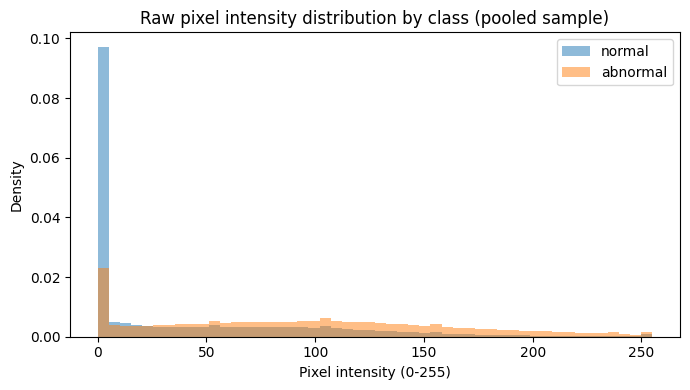

A visibly shifted histogram between classes (not just a texture/shape difference, but the whole brightness distribution) supports a global acquisition/preprocessing confound.


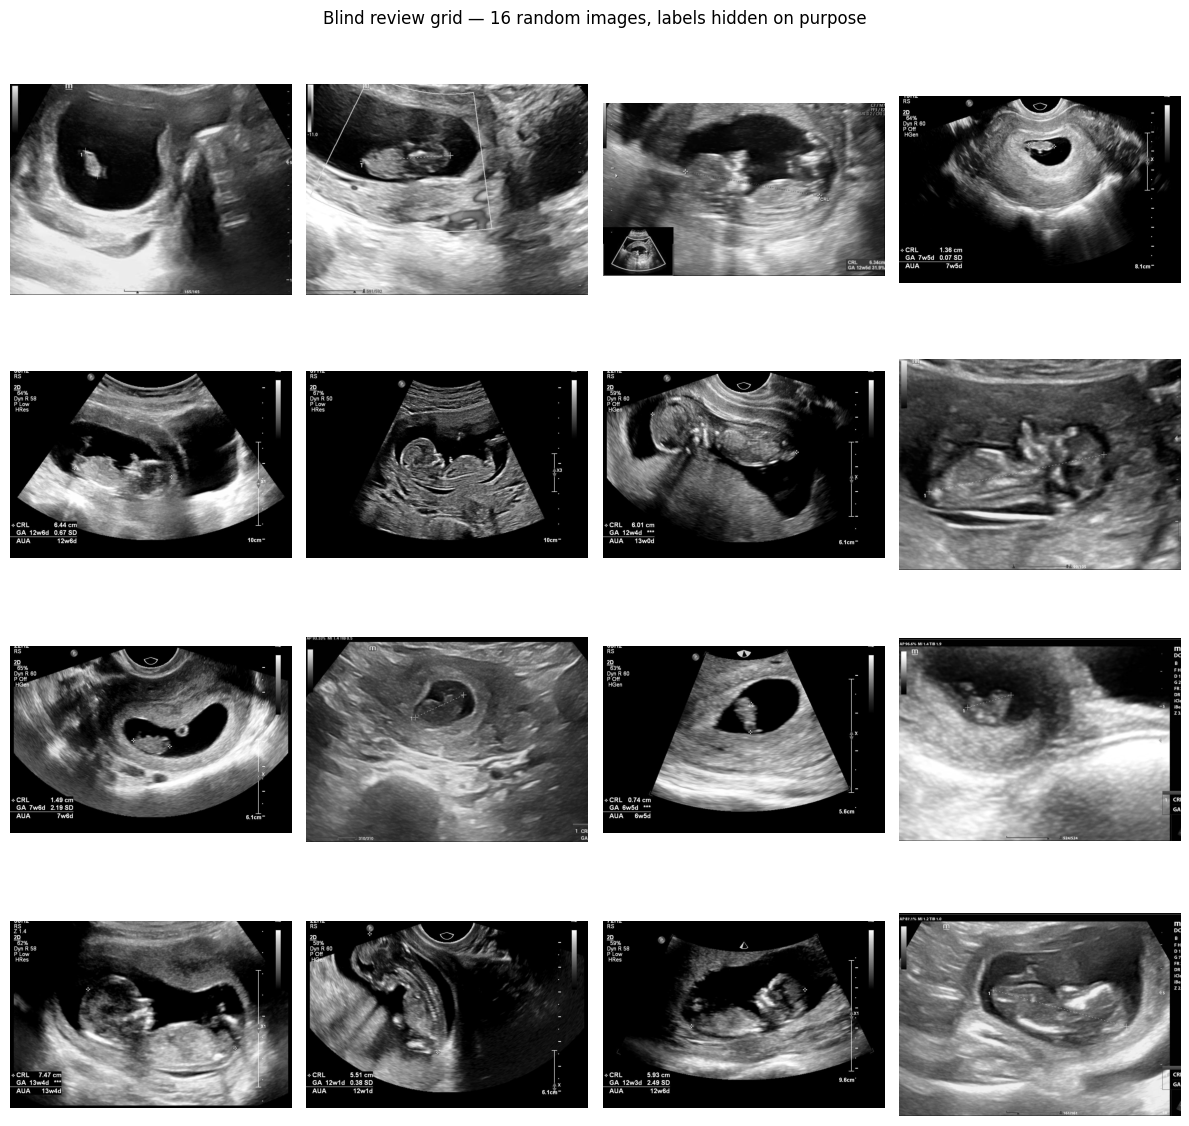


Look at the grid above WITHOUT the answer key first. Ask: do any images have visible calipers/arrows/text/markers? Different borders, cropping, brightness, or zoom level? Different ultrasound machine UI overlays? Anything that would tell you the class *without* looking at anatomy?

Run the cell below only after you've formed your own impression.


In [20]:
import random

# ---- 1. Raw image dimensions / aspect ratio / file format, BEFORE resize, by class ----
from PIL import Image as PILImage

dim_rows = []
for split_name, samples in [("train", train_samples), ("test", test_samples)]:
    for path, label in samples:
        with PILImage.open(path) as im:
            w, h = im.size
            mode = im.mode
            fmt = im.format
        dim_rows.append({
            "split": split_name, "label": CLASS_NAMES[label], "filepath": path,
            "width": w, "height": h, "aspect_ratio": w / h, "mode": mode, "format": fmt,
        })
dim_df = pd.DataFrame(dim_rows)
dim_df.to_csv(TAB_DIR / "raw_image_metadata_by_class.csv", index=False)

print("Raw image size/format by class (before IMG_SIZE resize):")
print(dim_df.groupby("label")[["width", "height", "aspect_ratio"]].describe().T)
print("\nFile format / color mode by class:")
print(pd.crosstab(dim_df["label"], dim_df["format"]))
print(pd.crosstab(dim_df["label"], dim_df["mode"]))
print(
    "\n>>> If width/height/aspect_ratio/format/mode differ systematically by class, that alone "
    "can produce near-ceiling AUC with zero anatomical signal — e.g. differently-sized source "
    "images resize/interpolate differently and shift texture statistics."
)

# ---- 2. Raw pixel-intensity histogram overlay, by class (whole image, unresized) ----
plt.figure(figsize=(7, 4))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    paths = [p for p, l in (train_samples + test_samples) if l == cls_idx]
    sample_paths = random.sample(paths, min(60, len(paths)))
    pooled_pixels = np.concatenate([
        np.asarray(PILImage.open(p).convert("L")).ravel() for p in sample_paths
    ])
    plt.hist(pooled_pixels, bins=50, alpha=0.5, density=True, label=cls_name)
plt.xlabel("Pixel intensity (0-255)")
plt.ylabel("Density")
plt.title("Raw pixel intensity distribution by class (pooled sample)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "raw_pixel_intensity_by_class.png", dpi=300)
plt.show()
print(
    "A visibly shifted histogram between classes (not just a texture/shape difference, but "
    "the whole brightness distribution) supports a global acquisition/preprocessing confound."
)

# ---- 3. Blind, shuffled, UNLABELED image grid for manual visual review ----
# Deliberately does not print which image is which class until AFTER you've looked.
review_pool = [(p, CLASS_NAMES[l]) for p, l in (train_samples + test_samples)]
random.seed(SEED)
random.shuffle(review_pool)
review_sample = review_pool[:16]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, (path, _) in zip(axes.ravel(), review_sample):
    img = PILImage.open(path).convert("L")
    ax.imshow(img, cmap="gray")
    ax.axis("off")
plt.suptitle("Blind review grid — 16 random images, labels hidden on purpose")
plt.tight_layout()
plt.savefig(FIG_DIR / "blind_review_grid.png", dpi=300)
plt.show()

print(
    "\nLook at the grid above WITHOUT the answer key first. Ask: do any images have visible "
    "calipers/arrows/text/markers? Different borders, cropping, brightness, or zoom level? "
    "Different ultrasound machine UI overlays? Anything that would tell you the class *without* "
    "looking at anatomy?\n\nRun the cell below only after you've formed your own impression."
)


In [21]:
# Answer key for the blind grid above (run only after visual review)
answer_key = pd.DataFrame(
    [{"position": i, "filepath": p, "true_label": lbl} for i, (p, lbl) in enumerate(review_sample)]
)
print(answer_key.to_string(index=False))


 position                                 filepath true_label
        0 dataset\train\abnormal\Abnormal_0012.jpg   abnormal
        1 dataset\train\abnormal\Abnormal_0300.jpg   abnormal
        2     dataset\train\normal\Normal_0033.jpg     normal
        3      dataset\test\normal\Normal_0186.jpg     normal
        4      dataset\test\normal\Normal_0069.jpg     normal
        5     dataset\train\normal\Normal_0147.jpg     normal
        6      dataset\test\normal\Normal_0084.jpg     normal
        7  dataset\test\abnormal\Abnormal_0070.jpg   abnormal
        8      dataset\test\normal\Normal_0215.jpg     normal
        9  dataset\test\abnormal\Abnormal_0136.jpg   abnormal
       10      dataset\test\normal\Normal_0225.jpg     normal
       11 dataset\train\abnormal\Abnormal_0248.jpg   abnormal
       12     dataset\train\normal\Normal_0098.jpg     normal
       13      dataset\test\normal\Normal_0233.jpg     normal
       14      dataset\test\normal\Normal_0143.jpg     normal
       1

## 20. Confound quantification — how much signal comes from size/format alone?
The dimension/format check in Section 19 found systematically different image sizes,
aspect ratios, and file formats between classes. This cell trains a trivial classifier on
**only** that metadata (width, height, aspect ratio, format) — no pixel content at all — to
put a number on how much of the "diagnostic" signal could be explained by source/export
pipeline differences alone rather than anatomy.


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

meta_df = dim_df.copy()
meta_df["is_png"] = (meta_df["format"] == "PNG").astype(int)
meta_df["y"] = (meta_df["label"] == "abnormal").astype(int)

meta_features = ["width", "height", "aspect_ratio", "is_png"]
X_meta = meta_df[meta_features].values
y_meta = meta_df["y"].values

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf_meta = LogisticRegression(max_iter=1000, class_weight="balanced")
auc_scores = cross_val_score(clf_meta, X_meta, y_meta, cv=cv, scoring="roc_auc")

print(f"5-fold CV AUC using ONLY image size/aspect-ratio/format (no pixel content): "
      f"{auc_scores.mean():.4f} +/- {auc_scores.std():.4f}")
print(
    "\nIf this AUC is high (e.g. > 0.85), it means metadata that has nothing to do with "
    "anatomy already explains most of what your radiomics models are picking up. In that "
    "case the 0.95-0.99 AUCs reported in Section 8 cannot be interpreted as diagnostic "
    "performance until the confound is removed at the data level (matched/resampled source "
    "pipeline per class, or images re-exported through one consistent pipeline)."
)


5-fold CV AUC using ONLY image size/aspect-ratio/format (no pixel content): 1.0000 +/- 0.0000

If this AUC is high (e.g. > 0.85), it means metadata that has nothing to do with anatomy already explains most of what your radiomics models are picking up. In that case the 0.95-0.99 AUCs reported in Section 8 cannot be interpreted as diagnostic performance until the confound is removed at the data level (matched/resampled source pipeline per class, or images re-exported through one consistent pipeline).


## 21. Source-cluster inference + cross-source evaluation protocol
Since (width, height, format) perfectly predicts class (Section 20), those attributes are
almost certainly a proxy for **image source/export batch**, not chance. This section:
1. Groups images into inferred source clusters using their exact (width, height, format).
2. Shows whether any cluster contains **both** classes in meaningful numbers — this
   determines whether a matched/controlled analysis is even possible with your current data.
3. If clusters are cleanly separated by class (no meaningful overlap), it runs the honest
   fallback: **leave-one-source-out evaluation**, so you get a real, defensible number for
   "how well does this generalize across sources" instead of a pooled number that's
   confounded by source.

Read the printed crosstab carefully before trusting anything downstream of this cell.


In [23]:
# ---- 1. Infer source clusters from exact (width, height, format) ----
dim_df["source_cluster"] = (
    dim_df["width"].astype(str) + "x" + dim_df["height"].astype(str) + "_" + dim_df["format"]
)

cluster_counts = dim_df.groupby(["source_cluster", "label"]).size().unstack(fill_value=0)
cluster_counts["total"] = cluster_counts.sum(axis=1)
cluster_counts = cluster_counts.sort_values("total", ascending=False)
print("Inferred source clusters (exact width x height _ format) by class:")
print(cluster_counts)

# ---- 2. Does any cluster contain BOTH classes in meaningful numbers? ----
MIN_PER_CLASS = 10  # need at least this many of each class within a cluster to trust a matched comparison
mixed_clusters = cluster_counts[
    (cluster_counts.get("normal", 0) >= MIN_PER_CLASS)
    & (cluster_counts.get("abnormal", 0) >= MIN_PER_CLASS)
]

if len(mixed_clusters):
    print(f"\n{len(mixed_clusters)} cluster(s) contain >= {MIN_PER_CLASS} of BOTH classes — "
          f"a matched, source-controlled analysis is possible. See mixed_clusters below.")
    print(mixed_clusters)
    print(
        "\nNext step: re-run Sections 6-8 (modeling) restricted to ONLY the images in these "
        "mixed cluster(s). If AUC stays high on this source-matched subset, that is much "
        "stronger evidence of a genuine anatomical signal, independent of the confound."
    )
else:
    print(
        f"\nNo cluster contains >= {MIN_PER_CLASS} of both classes — classes are essentially "
        "cleanly separated by source in this dataset. A matched/controlled analysis is NOT "
        "possible with the current data. You need either (a) new, source-balanced data, or "
        "(b) to reframe the study as a cross-source generalization question (Section 21b below)."
    )


Inferred source clusters (exact width x height _ format) by class:
label           abnormal  normal  total
source_cluster                         
1024x683_JPEG          0     261    261
685x515_JPEG         173       0    173
640x395_JPEG           0      66     66
685x515_PNG           64       0     64
1145x825_JPEG         53       0     53
1145x835_JPEG         27       0     27
1085x815_JPEG          8       0      8
1260x835_JPEG          0       4      4
800x515_JPEG           0       1      1

No cluster contains >= 10 of both classes — classes are essentially cleanly separated by source in this dataset. A matched/controlled analysis is NOT possible with the current data. You need either (a) new, source-balanced data, or (b) to reframe the study as a cross-source generalization question (Section 21b below).


In [24]:
# ---- 3. Fallback: leave-one-source-out evaluation (only meaningful if there are >=2 real sources per class,
#         or if you can obtain/assign TRUE site/scanner labels rather than inferred size/format clusters).
#         This is a template — swap `dim_df["source_cluster"]` for a real site/scanner column if you get one.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Merge source_cluster onto the feature tables via filepath
train_src = radiomics_train_df.merge(
    dim_df[["filepath", "source_cluster"]], on="filepath", how="left"
)
test_src = radiomics_test_df.merge(
    dim_df[["filepath", "source_cluster"]], on="filepath", how="left"
)
all_src_df = pd.concat([train_src, test_src], ignore_index=True)

print("Available source clusters and class balance within each (for evaluating generalization):")
print(all_src_df.groupby("source_cluster")["label"].value_counts().unstack(fill_value=0))

print(
    "\nIf you obtain TRUE site/scanner labels (not just inferred from image size/format), "
    "replace `source_cluster` above with that column and run a proper leave-one-site-out "
    "loop: for each site, train on all other sites, test on the held-out site, and report "
    "AUC per held-out site. That is the honest number for how well this approach generalizes "
    "across acquisition sources -- and is a publishable result in its own right, clearly "
    "reported as a cross-source/cross-scanner generalization study rather than a pooled "
    "diagnostic-accuracy claim."
)


Available source clusters and class balance within each (for evaluating generalization):
label             0    1
source_cluster          
1024x683_JPEG   261    0
1085x815_JPEG     0    8
1145x825_JPEG     0   53
1145x835_JPEG     0   27
1260x835_JPEG     4    0
640x395_JPEG     66    0
685x515_JPEG      0  173
685x515_PNG       0   64
800x515_JPEG      1    0

If you obtain TRUE site/scanner labels (not just inferred from image size/format), replace `source_cluster` above with that column and run a proper leave-one-site-out loop: for each site, train on all other sites, test on the held-out site, and report AUC per held-out site. That is the honest number for how well this approach generalizes across acquisition sources -- and is a publishable result in its own right, clearly reported as a cross-source/cross-scanner generalization study rather than a pooled diagnostic-accuracy claim.


## 22. Harmonization pipeline — remove capture/export-style confound before re-extracting features
Multi-hospital data legitimately varies in raw size/format — that alone isn't the problem;
the problem is that in this dataset it's **perfectly** collinear with the label (Section 20,
AUC=1.0). Two likely mechanisms, given normal images are one fixed 1024x683 JPEG layout
(consistent with a CRL measurement-report export) while abnormal images are multiple raw
capture sizes/formats across hospitals:

1. **Fixed UI/report elements** (patient info bar, caliper markers, "CRL: xx mm" caption,
   borders) baked into the normal measurement-report images but absent from abnormal raw
   captures.
2. **Naive `cv2.resize` to a fixed square** warping different native aspect ratios
   differently, which shifts GLCM texture statistics for reasons having nothing to do with
   anatomy.

This section addresses both: **(a)** auto-crops to the largest non-uniform content region
(strips likely borders/caption bars — best-effort, verify visually), **(b)** replaces the
naive resize with a **letterbox resize** (preserve aspect ratio, pad with black) so native
size no longer changes shape/texture asymmetrically. It then re-extracts features and
re-runs the confound diagnostics on the harmonized images.

**Before trusting anything downstream: save and manually look at `harmonized_examples.png`
below.** If the auto-crop is cutting into real anatomy, or leaving report text in place,
this needs manual tuning per hospital/machine before you proceed — don't skip that check.


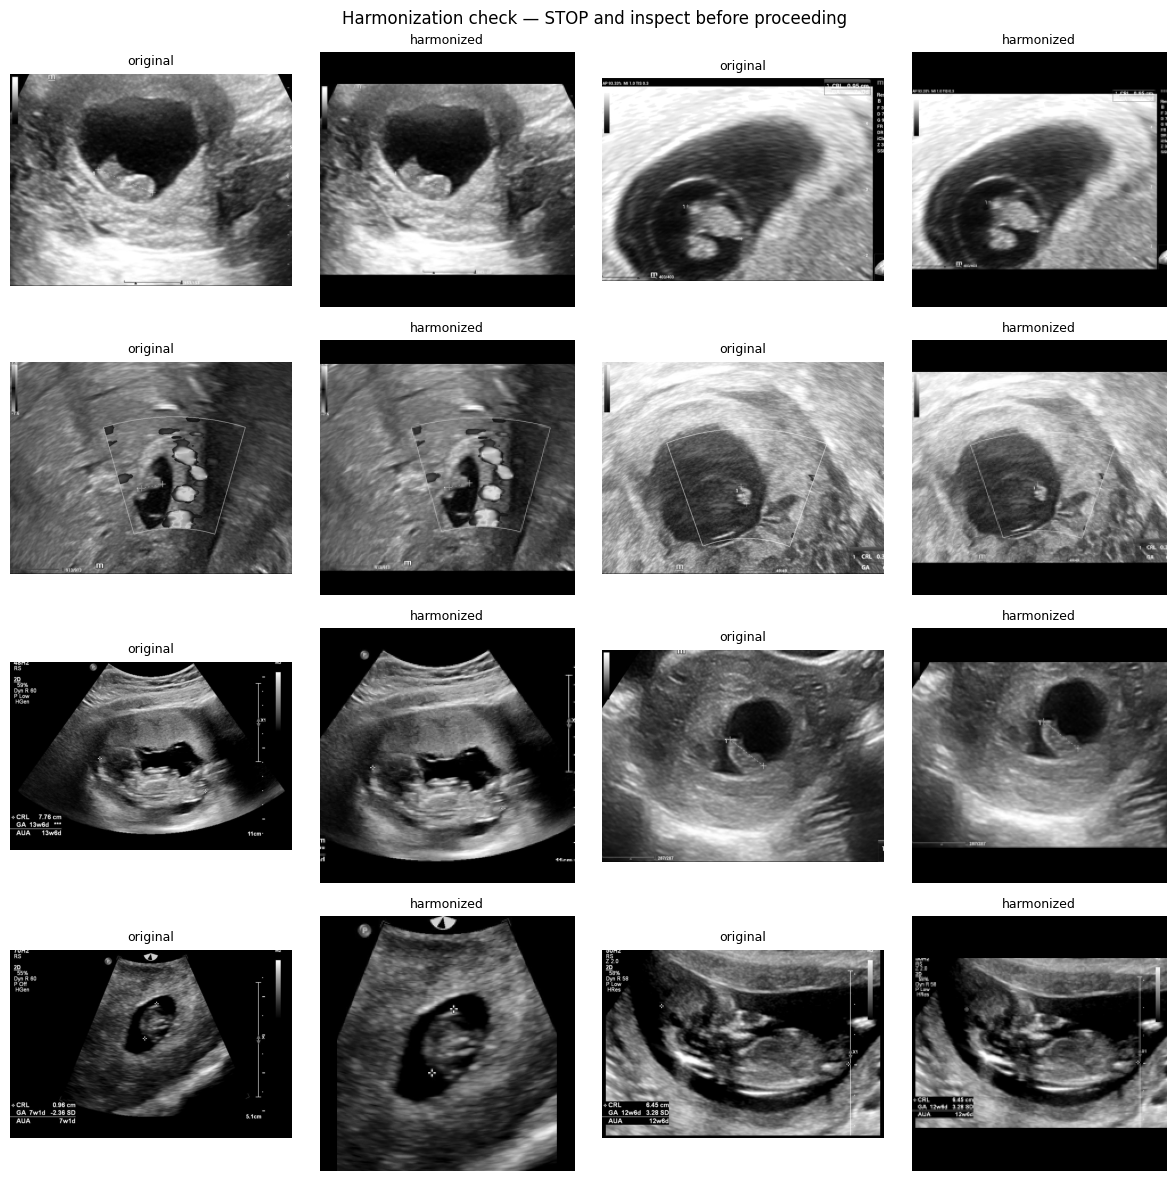

STOP: inspect harmonized_examples.png. Confirm (1) no real anatomy was cropped out, (2) any patient-info/caption bars ARE cropped out where present, (3) images aren't distorted. If the auto-crop looks wrong for some hospitals, tune min_area_frac or write a per-cluster crop rule before proceeding to re-extraction below.


In [25]:
import cv2

def auto_crop_scan_region(img_gray: np.ndarray, min_area_frac: float = 0.30) -> np.ndarray:
    """
    Best-effort crop to the largest non-uniform content region, to strip fixed borders /
    report caption bars that differ by export template. Falls back to the original image
    if no confident large region is found. VERIFY VISUALLY before trusting on your data.
    """
    h, w = img_gray.shape
    _, thresh = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img_gray
    largest = max(contours, key=cv2.contourArea)
    x, y, cw, ch = cv2.boundingRect(largest)
    if cw * ch < min_area_frac * h * w:
        return img_gray
    return img_gray[y:y + ch, x:x + cw]


def letterbox_resize(img_gray: np.ndarray, size: int = IMG_SIZE) -> np.ndarray:
    """Resize preserving aspect ratio, pad with black to a square — no directional warping."""
    h, w = img_gray.shape
    scale = size / max(h, w)
    new_h, new_w = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img_gray, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((size, size), dtype=resized.dtype)
    y_off, x_off = (size - new_h) // 2, (size - new_w) // 2
    canvas[y_off:y_off + new_h, x_off:x_off + new_w] = resized
    return canvas


def harmonize_image(image_path: str) -> np.ndarray:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(image_path)
    img = auto_crop_scan_region(img)
    img = letterbox_resize(img, IMG_SIZE)
    return img


# ---- Visual check FIRST: before/after grid for a few images per cluster ----
review_paths = (
    dim_df.sort_values("total" if "total" in dim_df.columns else "source_cluster")
    .groupby("source_cluster")
    .first()["filepath"] if "source_cluster" in dim_df.columns else None
)
sample_check_paths = [p for p, _ in random.sample(train_samples + test_samples, 8)]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for row, path in enumerate(sample_check_paths[:4]):
    orig = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    harm = harmonize_image(path)
    axes[row, 0].imshow(orig, cmap="gray"); axes[row, 0].set_title("original", fontsize=9)
    axes[row, 1].imshow(harm, cmap="gray"); axes[row, 1].set_title("harmonized", fontsize=9)
    axes[row, 0].axis("off"); axes[row, 1].axis("off")
for row, path in enumerate(sample_check_paths[4:]):
    orig = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    harm = harmonize_image(path)
    axes[row, 2].imshow(orig, cmap="gray"); axes[row, 2].set_title("original", fontsize=9)
    axes[row, 3].imshow(harm, cmap="gray"); axes[row, 3].set_title("harmonized", fontsize=9)
    axes[row, 2].axis("off"); axes[row, 3].axis("off")
plt.suptitle("Harmonization check — STOP and inspect before proceeding")
plt.tight_layout()
plt.savefig(FIG_DIR / "harmonized_examples.png", dpi=300)
plt.show()

print(
    "STOP: inspect harmonized_examples.png. Confirm (1) no real anatomy was cropped out, "
    "(2) any patient-info/caption bars ARE cropped out where present, (3) images aren't "
    "distorted. If the auto-crop looks wrong for some hospitals, tune min_area_frac or "
    "write a per-cluster crop rule before proceeding to re-extraction below."
)


In [26]:
# ---- Re-extract radiomic features on HARMONIZED images (same feature logic as Section 4) ----

def extract_radiomic_features_harmonized(image_path: str) -> dict:
    img = harmonize_image(image_path)
    feats = {}
    feats["mean"] = float(np.mean(img))
    feats["std"] = float(np.std(img))
    feats["variance"] = float(np.var(img))
    feats["skewness"] = float(pd.Series(img.ravel()).skew())
    feats["kurtosis"] = float(pd.Series(img.ravel()).kurtosis())
    feats["entropy"] = float(shannon_entropy(img))
    feats["energy_mean_sq"] = float(np.mean(img.astype(np.float64) ** 2))
    feats["min"] = float(np.min(img))
    feats["max"] = float(np.max(img))
    p10, p25, p75, p90 = np.percentile(img, [10, 25, 75, 90])
    feats["p10"], feats["p25"], feats["p75"], feats["p90"] = map(float, (p10, p25, p75, p90))

    img_q = (img.astype(np.float64) / 256.0 * 32).astype(np.uint8)
    distances = [1, 3]
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(img_q, distances=distances, angles=angles,
                         levels=32, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        vals = graycoprops(glcm, prop)
        feats[f"glcm_{prop}_mean"] = float(np.mean(vals))
        feats[f"glcm_{prop}_std"] = float(np.std(vals))
    return feats


def build_feature_table_harmonized(samples):
    rows = []
    for path, label in samples:
        feats = extract_radiomic_features_harmonized(path)
        feats["label"] = label
        feats["filepath"] = path
        rows.append(feats)
    return pd.DataFrame(rows)


print("Re-extracting radiomic features on HARMONIZED images (train)...")
radiomics_train_df_h = build_feature_table_harmonized(train_samples)
print("Re-extracting radiomic features on HARMONIZED images (test)...")
radiomics_test_df_h = build_feature_table_harmonized(test_samples)
print(f"Harmonized train features: {radiomics_train_df_h.shape}, test: {radiomics_test_df_h.shape}")


Re-extracting radiomic features on HARMONIZED images (train)...
Re-extracting radiomic features on HARMONIZED images (test)...
Harmonized train features: (459, 27), test: (198, 27)


In [27]:
# ---- Re-run the confound diagnostics (Sections 17 & 20 equivalents) on HARMONIZED features ----

# (a) single-feature AUC check, harmonized
feat_check_rows_h = []
for feat in feature_cols:
    vals = radiomics_test_df_h[feat].values
    try:
        auc = roc_auc_score(y_test, vals)
        auc = max(auc, 1 - auc)
    except Exception:
        auc = np.nan
    feat_check_rows_h.append({"feature": feat, "single_feature_auc_test_harmonized": auc})

feat_check_df_h = pd.DataFrame(feat_check_rows_h).sort_values(
    "single_feature_auc_test_harmonized", ascending=False
)
feat_check_df_h.to_csv(TAB_DIR / "single_feature_auc_shortcut_check_harmonized.csv", index=False)
print("Top single features by AUC alone, HARMONIZED images:")
print(feat_check_df_h.head(10).to_string(index=False))

n_flagged_h = (feat_check_df_h["single_feature_auc_test_harmonized"] > HIGH_AUC_THRESHOLD).sum()
print(f"\nFeatures still exceeding AUC={HIGH_AUC_THRESHOLD} alone after harmonization: {n_flagged_h}")
print("Compare directly to the pre-harmonization Section 17 output above this cell in your run history.")

# (b) does raw post-crop content shape still leak class? -- recompute size AFTER auto-crop only (before letterbox)
postcrop_rows = []
for split_name, samples in [("train", train_samples), ("test", test_samples)]:
    for path, label in samples:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        cropped = auto_crop_scan_region(img)
        ch, cw = cropped.shape
        postcrop_rows.append({"filepath": path, "label": CLASS_NAMES[label],
                               "postcrop_width": cw, "postcrop_height": ch,
                               "postcrop_aspect": cw / ch})
postcrop_df = pd.DataFrame(postcrop_rows)
postcrop_df.to_csv(TAB_DIR / "postcrop_dimensions_by_class.csv", index=False)

X_meta_h = postcrop_df[["postcrop_width", "postcrop_height", "postcrop_aspect"]].values
y_meta_h = (postcrop_df["label"] == "abnormal").astype(int).values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf_meta_h = LogisticRegression(max_iter=1000, class_weight="balanced")
auc_scores_h = cross_val_score(clf_meta_h, X_meta_h, y_meta_h, cv=cv, scoring="roc_auc")
print(f"\n5-fold CV AUC from POST-CROP size/aspect alone (harmonized pipeline): "
      f"{auc_scores_h.mean():.4f} +/- {auc_scores_h.std():.4f}")
print(
    "This is your key go/no-go number. Compare to the pre-harmonization Section 20 result "
    "(AUC=1.0000). If this has dropped substantially (ideally toward ~0.5-0.6), harmonization "
    "is working and you can proceed to re-run full modeling (Sections 6-15) using "
    "radiomics_train_df_h / radiomics_test_df_h in place of the original feature tables. "
    "If it is still high, the crop/resize fix alone is not enough -- go back to Section 22's "
    "visual check and either tune the crop per hospital or treat this as a Path C / Path B "
    "situation (new matched data, or an explicitly cross-hospital study design)."
)


Top single features by AUC alone, HARMONIZED images:
              feature  single_feature_auc_test_harmonized
         glcm_ASM_std                            0.934898
                 mean                            0.931122
              entropy                            0.911020
       energy_mean_sq                            0.909898
             skewness                            0.901429
                  p75                            0.901327
glcm_correlation_mean                            0.894082
     glcm_energy_mean                            0.883469
        glcm_ASM_mean                            0.883265
                  p90                            0.870510

Features still exceeding AUC=0.9 alone after harmonization: 6
Compare directly to the pre-harmonization Section 17 output above this cell in your run history.

5-fold CV AUC from POST-CROP size/aspect alone (harmonized pipeline): 0.5681 +/- 0.0297
This is your key go/no-go number. Compare to the pre-harmoni

## 23. Remaining-signal check — brightness/gain confound vs. real pathology
Harmonization removed the size/format confound (post-crop metadata AUC dropped to ~0.57),
but 6 features dominated by overall brightness/contrast/homogeneity (`mean`, `entropy`,
`energy_mean_sq`, `skewness`, `p75`, `glcm_ASM_std`) still separate classes almost alone.
This does NOT necessarily mean another confound — fetal demise can genuinely alter tissue
echogenicity. This section gives you the evidence to tell the two apart:
1. A brightness/gain histogram comparison on the HARMONIZED images (same crop, same
   resize — isolates whether overall image brightness differs by class even after removing
   size effects).
2. A blind visual grid of HARMONIZED images (post-crop, post-letterbox) — the fairest
   version of the visual check, since export-layout differences are now removed.


Harmonized-image mean pixel intensity, by class (test set):
          count       mean        std        min        25%        50%  \
label                                                                    
abnormal   98.0  78.713855  21.270149  25.818200  64.797742  76.903838   
normal    100.0  41.780457  13.375702  11.357223  32.728227  40.903649   

                75%         max  
label                            
abnormal  93.744295  139.031290  
normal    48.574518   91.003288  


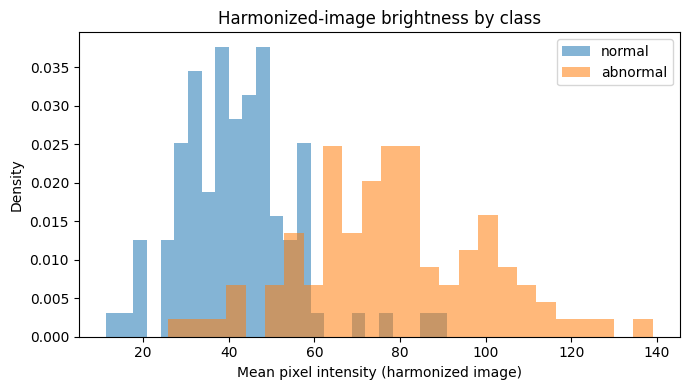


If these two distributions are cleanly separated (little overlap), that is still consistent with EITHER a genuine echogenicity difference in fetal demise, OR leftover gain/preset differences in acquisition. The histogram alone cannot distinguish them -- the blind visual check below, plus your clinical judgment as the person who scanned these patients, is what actually resolves this.


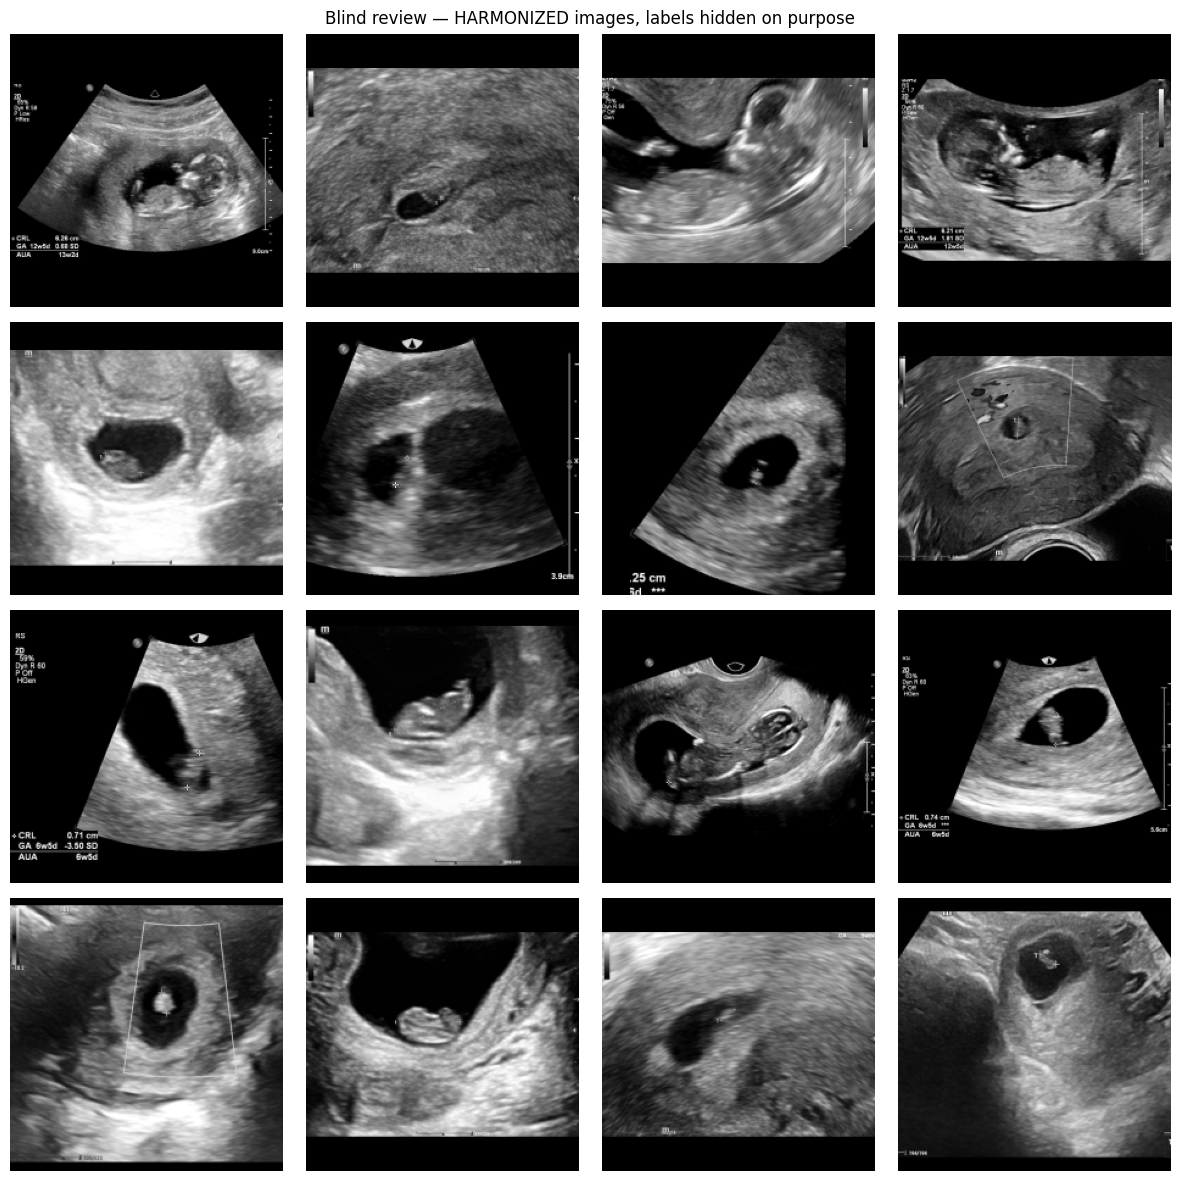

Look at brightness/gain/contrast ONLY (ignore anatomy/pathology judgment for a moment): do the images look like they came from consistent acquisition settings, or do some look visibly brighter/darker/higher-gain as a GROUP? Then check the answer key below and see if that grouping lines up with class.


In [28]:
# ---- 1. Brightness/gain distribution on HARMONIZED images, by class ----
mean_by_class_h = radiomics_test_df_h.groupby(
    pd.Series(y_test, name="label").map({0: "normal", 1: "abnormal"})
)["mean"].describe()
print("Harmonized-image mean pixel intensity, by class (test set):")
print(mean_by_class_h)

plt.figure(figsize=(7, 4))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    vals = radiomics_test_df_h.loc[y_test == cls_idx, "mean"]
    plt.hist(vals, bins=25, alpha=0.55, density=True, label=cls_name)
plt.xlabel("Mean pixel intensity (harmonized image)")
plt.ylabel("Density")
plt.title("Harmonized-image brightness by class")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "harmonized_brightness_by_class.png", dpi=300)
plt.show()

print(
    "\nIf these two distributions are cleanly separated (little overlap), that is still "
    "consistent with EITHER a genuine echogenicity difference in fetal demise, OR leftover "
    "gain/preset differences in acquisition. The histogram alone cannot distinguish them -- "
    "the blind visual check below, plus your clinical judgment as the person who scanned "
    "these patients, is what actually resolves this."
)

# ---- 2. Blind visual grid on HARMONIZED images ----
random.seed(SEED + 1)
review_pool_h = list(zip(train_samples + test_samples, [None] * (len(train_samples) + len(test_samples))))
all_samples = train_samples + test_samples
idx_sample = random.sample(range(len(all_samples)), 16)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, idx in zip(axes.ravel(), idx_sample):
    path, _ = all_samples[idx]
    harm = harmonize_image(path)
    ax.imshow(harm, cmap="gray")
    ax.axis("off")
plt.suptitle("Blind review — HARMONIZED images, labels hidden on purpose")
plt.tight_layout()
plt.savefig(FIG_DIR / "blind_review_grid_harmonized.png", dpi=300)
plt.show()

print(
    "Look at brightness/gain/contrast ONLY (ignore anatomy/pathology judgment for a moment): "
    "do the images look like they came from consistent acquisition settings, or do some look "
    "visibly brighter/darker/higher-gain as a GROUP? Then check the answer key below and see "
    "if that grouping lines up with class."
)


In [29]:
answer_key_h = pd.DataFrame(
    [{"position": i, "filepath": all_samples[idx][0],
      "true_label": CLASS_NAMES[all_samples[idx][1]]} for i, idx in enumerate(idx_sample)]
)
print(answer_key_h.to_string(index=False))


 position                                 filepath true_label
        0     dataset\train\normal\Normal_0060.jpg     normal
        1 dataset\train\abnormal\Abnormal_0091.jpg   abnormal
        2     dataset\train\normal\Normal_0212.jpg     normal
        3      dataset\test\normal\Normal_0050.jpg     normal
        4 dataset\train\abnormal\Abnormal_0213.png   abnormal
        5     dataset\train\normal\Normal_0144.jpg     normal
        6      dataset\test\normal\Normal_0016.jpg     normal
        7  dataset\test\abnormal\Abnormal_0177.png   abnormal
        8      dataset\test\normal\Normal_0176.jpg     normal
        9  dataset\test\abnormal\Abnormal_0207.jpg   abnormal
       10     dataset\train\normal\Normal_0029.jpg     normal
       11      dataset\test\normal\Normal_0225.jpg     normal
       12 dataset\train\abnormal\Abnormal_0298.jpg   abnormal
       13  dataset\test\abnormal\Abnormal_0099.jpg   abnormal
       14 dataset\train\abnormal\Abnormal_0219.jpg   abnormal
       1

## 24. Brightness/gain normalization — second harmonization pass
Post-crop images still show a near-2x, almost-non-overlapping mean-intensity gap between
classes (41.8 vs 78.7) — too large and too clean to confidently call biological echogenicity
change rather than a gain/export-template difference. This adds **per-image percentile-based
intensity normalization** (stretches each image's own 1st-99th percentile to 0-255) on top of
the crop+letterbox harmonization, which removes global brightness/gain differences while
preserving *relative* contrast/texture within each image. Re-extracts features, then re-checks
whether brightness-driven separability collapses and whether meaningful texture signal remains.


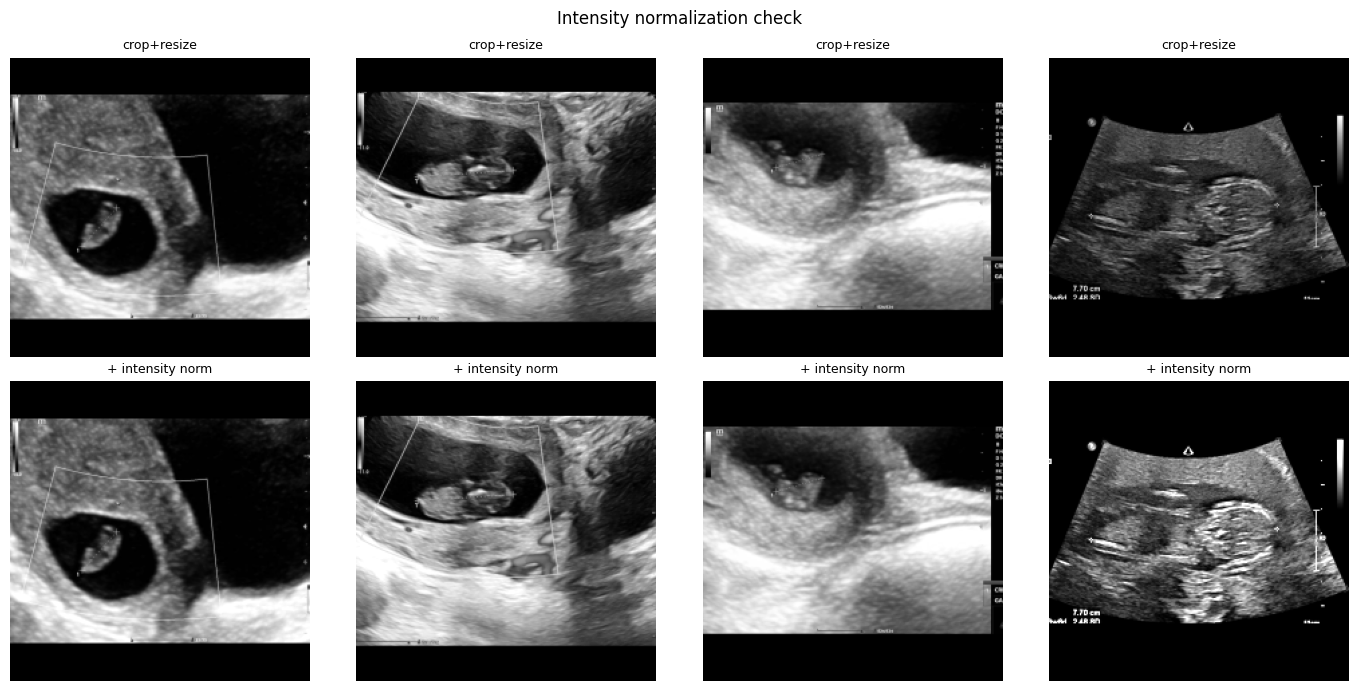

Re-extracting features on crop+letterbox+intensity-normalized images...
v2 harmonized train: (459, 27), test: (198, 27)


In [30]:
def normalize_intensity(img_gray: np.ndarray, low_pct: float = 1, high_pct: float = 99) -> np.ndarray:
    """Per-image percentile stretch — removes global brightness/gain, keeps relative contrast."""
    lo, hi = np.percentile(img_gray, [low_pct, high_pct])
    if hi <= lo:
        return img_gray
    stretched = np.clip((img_gray.astype(np.float64) - lo) / (hi - lo), 0, 1) * 255.0
    return stretched.astype(np.uint8)


def harmonize_image_v2(image_path: str) -> np.ndarray:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(image_path)
    img = auto_crop_scan_region(img)
    img = letterbox_resize(img, IMG_SIZE)
    img = normalize_intensity(img)
    return img


def extract_radiomic_features_harmonized_v2(image_path: str) -> dict:
    img = harmonize_image_v2(image_path)
    feats = {}
    feats["mean"] = float(np.mean(img))
    feats["std"] = float(np.std(img))
    feats["variance"] = float(np.var(img))
    feats["skewness"] = float(pd.Series(img.ravel()).skew())
    feats["kurtosis"] = float(pd.Series(img.ravel()).kurtosis())
    feats["entropy"] = float(shannon_entropy(img))
    feats["energy_mean_sq"] = float(np.mean(img.astype(np.float64) ** 2))
    feats["min"] = float(np.min(img))
    feats["max"] = float(np.max(img))
    p10, p25, p75, p90 = np.percentile(img, [10, 25, 75, 90])
    feats["p10"], feats["p25"], feats["p75"], feats["p90"] = map(float, (p10, p25, p75, p90))

    img_q = (img.astype(np.float64) / 256.0 * 32).astype(np.uint8)
    distances = [1, 3]
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(img_q, distances=distances, angles=angles,
                         levels=32, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        vals = graycoprops(glcm, prop)
        feats[f"glcm_{prop}_mean"] = float(np.mean(vals))
        feats[f"glcm_{prop}_std"] = float(np.std(vals))
    return feats


def build_feature_table_harmonized_v2(samples):
    rows = []
    for path, label in samples:
        feats = extract_radiomic_features_harmonized_v2(path)
        feats["label"] = label
        feats["filepath"] = path
        rows.append(feats)
    return pd.DataFrame(rows)


# ---- Visual check first ----
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
sample_check_paths2 = [p for p, _ in random.sample(train_samples + test_samples, 4)]
for col, path in enumerate(sample_check_paths2):
    before = harmonize_image(path)      # crop + letterbox only
    after = harmonize_image_v2(path)    # + intensity normalization
    axes[0, col].imshow(before, cmap="gray"); axes[0, col].set_title("crop+resize", fontsize=9)
    axes[1, col].imshow(after, cmap="gray"); axes[1, col].set_title("+ intensity norm", fontsize=9)
    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.suptitle("Intensity normalization check")
plt.tight_layout()
plt.savefig(FIG_DIR / "intensity_norm_check.png", dpi=300)
plt.show()

print("Re-extracting features on crop+letterbox+intensity-normalized images...")
radiomics_train_df_h2 = build_feature_table_harmonized_v2(train_samples)
radiomics_test_df_h2 = build_feature_table_harmonized_v2(test_samples)
print(f"v2 harmonized train: {radiomics_train_df_h2.shape}, test: {radiomics_test_df_h2.shape}")


In [31]:
# ---- Re-check brightness separability and single-feature shortcut AUC, v2 harmonized ----
mean_by_class_h2 = radiomics_test_df_h2.groupby(
    pd.Series(y_test, name="label").map({0: "normal", 1: "abnormal"})
)["mean"].describe()
print("v2-harmonized mean pixel intensity, by class (test set):")
print(mean_by_class_h2)

feat_check_rows_h2 = []
for feat in feature_cols:
    vals = radiomics_test_df_h2[feat].values
    try:
        auc = roc_auc_score(y_test, vals)
        auc = max(auc, 1 - auc)
    except Exception:
        auc = np.nan
    feat_check_rows_h2.append({"feature": feat, "single_feature_auc_test_v2": auc})

feat_check_df_h2 = pd.DataFrame(feat_check_rows_h2).sort_values("single_feature_auc_test_v2", ascending=False)
feat_check_df_h2.to_csv(TAB_DIR / "single_feature_auc_shortcut_check_v2.csv", index=False)
print("\nTop single features by AUC alone, v2 (crop+resize+intensity-normalized):")
print(feat_check_df_h2.head(10).to_string(index=False))

n_flagged_h2 = (feat_check_df_h2["single_feature_auc_test_v2"] > HIGH_AUC_THRESHOLD).sum()
print(f"\nFeatures still exceeding AUC={HIGH_AUC_THRESHOLD} alone: {n_flagged_h2} "
      f"(was 9 originally, 6 after crop+letterbox only)")

print(
    "\nGO / NO-GO:\n"
    "- Brightness gap (mean, by class) should now be much smaller / overlapping.\n"
    "- If single-feature AUCs have dropped toward the 0.6-0.8 range with few/no features "
    "  still > 0.90, you likely have real signal left and can proceed to full modeling on "
    "  radiomics_train_df_h2 / radiomics_test_df_h2.\n"
    "- If several features are STILL > 0.90 even after removing size, crop, AND brightness "
    "  confounds, that remaining signal is much more likely to be genuine texture-level "
    "  anatomical difference (three independent confound sources removed) -- proceed, but "
    "  report all four harmonization/QA steps transparently in Methods.\n"
    "- If brightness is still nearly non-overlapping even after per-image normalization, "
    "  that would be unusual and worth a closer look at the normalize_intensity output "
    "  itself before concluding anything."
)


v2-harmonized mean pixel intensity, by class (test set):
          count       mean        std        min        25%        50%  \
label                                                                    
abnormal   98.0  89.165658  17.485394  43.970544  78.395717  87.652732   
normal    100.0  57.405740  14.560061  18.026028  46.475332  57.957231   

                 75%         max  
label                             
abnormal  101.373899  139.035894  
normal     66.650585  101.760922  

Top single features by AUC alone, v2 (crop+resize+intensity-normalized):
              feature  single_feature_auc_test_v2
                 mean                    0.919592
         glcm_ASM_std                    0.918367
       energy_mean_sq                    0.915612
              entropy                    0.913061
glcm_correlation_mean                    0.893469
             skewness                    0.893163
   glcm_contrast_mean                    0.892653
        glcm_ASM_mean           

## 25. Fix: remove zero-padding contamination from feature extraction
Bug found: Section 24's `letterbox_resize` pads with black to a square canvas, and features
were computed over the padded canvas — so `mean`/`entropy`/etc. were partly measuring how
much black padding each image got, which is itself aspect-ratio- (and possibly class-)
dependent. That's a second, self-inflicted confound layered on top of the first.

Fix: resize preserving aspect ratio to fit within `IMG_SIZE` (**no padding**), and extract
features directly from that image. GLCM/first-order stats don't require a square input.
Padding is only reintroduced for display, never for feature computation.


In [32]:
def aspect_preserving_resize(img_gray: np.ndarray, max_dim: int = IMG_SIZE) -> np.ndarray:
    """Resize so the longer side == max_dim, preserving aspect ratio. NO padding —
    avoids contaminating first-order/texture stats with background/padding pixels."""
    h, w = img_gray.shape
    scale = max_dim / max(h, w)
    new_h, new_w = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    return cv2.resize(img_gray, (new_w, new_h), interpolation=cv2.INTER_AREA)


def harmonize_image_v3(image_path: str) -> np.ndarray:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(image_path)
    img = auto_crop_scan_region(img)
    img = aspect_preserving_resize(img, IMG_SIZE)   # no padding
    img = normalize_intensity(img)
    return img


def extract_radiomic_features_harmonized_v3(image_path: str) -> dict:
    img = harmonize_image_v3(image_path)
    feats = {}
    feats["mean"] = float(np.mean(img))
    feats["std"] = float(np.std(img))
    feats["variance"] = float(np.var(img))
    feats["skewness"] = float(pd.Series(img.ravel()).skew())
    feats["kurtosis"] = float(pd.Series(img.ravel()).kurtosis())
    feats["entropy"] = float(shannon_entropy(img))
    feats["energy_mean_sq"] = float(np.mean(img.astype(np.float64) ** 2))
    feats["min"] = float(np.min(img))
    feats["max"] = float(np.max(img))
    p10, p25, p75, p90 = np.percentile(img, [10, 25, 75, 90])
    feats["p10"], feats["p25"], feats["p75"], feats["p90"] = map(float, (p10, p25, p75, p90))

    img_q = (img.astype(np.float64) / 256.0 * 32).astype(np.uint8)
    distances = [1, 3]
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(img_q, distances=distances, angles=angles,
                         levels=32, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        vals = graycoprops(glcm, prop)
        feats[f"glcm_{prop}_mean"] = float(np.mean(vals))
        feats[f"glcm_{prop}_std"] = float(np.std(vals))
    return feats


def build_feature_table_harmonized_v3(samples):
    rows = []
    for path, label in samples:
        feats = extract_radiomic_features_harmonized_v3(path)
        feats["label"] = label
        feats["filepath"] = path
        rows.append(feats)
    return pd.DataFrame(rows)


print("Re-extracting features: crop + aspect-preserving resize (NO padding) + intensity norm...")
radiomics_train_df_h3 = build_feature_table_harmonized_v3(train_samples)
radiomics_test_df_h3 = build_feature_table_harmonized_v3(test_samples)
print(f"v3 harmonized train: {radiomics_train_df_h3.shape}, test: {radiomics_test_df_h3.shape}")


Re-extracting features: crop + aspect-preserving resize (NO padding) + intensity norm...
v3 harmonized train: (459, 27), test: (198, 27)


In [33]:
# ---- Re-check brightness separability and single-feature shortcut AUC, v3 (padding-free) ----
mean_by_class_h3 = radiomics_test_df_h3.groupby(
    pd.Series(y_test, name="label").map({0: "normal", 1: "abnormal"})
)["mean"].describe()
print("v3-harmonized (no-padding) mean pixel intensity, by class (test set):")
print(mean_by_class_h3)

feat_check_rows_h3 = []
for feat in feature_cols:
    vals = radiomics_test_df_h3[feat].values
    try:
        auc = roc_auc_score(y_test, vals)
        auc = max(auc, 1 - auc)
    except Exception:
        auc = np.nan
    feat_check_rows_h3.append({"feature": feat, "single_feature_auc_test_v3": auc})

feat_check_df_h3 = pd.DataFrame(feat_check_rows_h3).sort_values("single_feature_auc_test_v3", ascending=False)
feat_check_df_h3.to_csv(TAB_DIR / "single_feature_auc_shortcut_check_v3.csv", index=False)
print("\nTop single features by AUC alone, v3 (crop + no-pad resize + intensity norm):")
print(feat_check_df_h3.head(10).to_string(index=False))

n_flagged_h3 = (feat_check_df_h3["single_feature_auc_test_v3"] > HIGH_AUC_THRESHOLD).sum()
print(f"\nFeatures still exceeding AUC={HIGH_AUC_THRESHOLD} alone: {n_flagged_h3} "
      f"(v1 crop only: 6, v2 crop+pad+norm: 4)")

print(
    "\nThis is the cleanest version of the pipeline so far (no padding contamination). "
    "Compare the brightness table above to v1/v2 -- if the gap has now shrunk substantially, "
    "the padding bug explains most of what looked like a stubborn brightness confound. "
    "Whatever separability remains after THIS check is the most credible candidate yet for "
    "genuine texture/pathology signal -- but given how many rounds of confound this dataset "
    "has needed, I'd still want it corroborated by the clinical literature on fetal-demise "
    "echogenicity before writing it up as a finding, not just an AUC number."
)


v3-harmonized (no-padding) mean pixel intensity, by class (test set):
          count        mean        std        min         25%         50%  \
label                                                                       
abnormal   98.0  116.341896  16.520375  78.005760  106.024595  114.857546   
normal    100.0   80.763400  20.314981  25.254195   67.631980   77.256909   

                 75%         max  
label                             
abnormal  126.794974  160.682894  
normal     94.013628  125.694932  

Top single features by AUC alone, v3 (crop + no-pad resize + intensity norm):
           feature  single_feature_auc_test_v3
           entropy                    0.930306
glcm_contrast_mean                    0.927551
               p25                    0.911888
              mean                    0.911122
      glcm_ASM_std                    0.905816
     glcm_ASM_mean                    0.896633
  glcm_energy_mean                    0.896531
    energy_mean_sq        

## 26. Cross-cluster consistency check (proxy for hospital, since true hospital ID is unavailable)
No per-image hospital label exists, so this uses the source-clusters from Section 21 (grouped
by original width/height/format, which plausibly proxy different machines/exports/hospitals)
as the best available stand-in. Logic: a REAL biological brightness/texture difference should
appear with similar magnitude across every abnormal cluster, regardless of which machine/export
produced it. A CONFOUND would instead be concentrated in specific clusters. This also checks
whether normal's own two sizeable clusters agree with each other, as an internal consistency
check on whether brightness is stable within a class across different capture pipelines.


In [34]:
# Merge v3-harmonized features with original source_cluster (from Section 21's dim_df)
train_v3_src = radiomics_train_df_h3.merge(dim_df[["filepath", "source_cluster"]], on="filepath", how="left")
test_v3_src = radiomics_test_df_h3.merge(dim_df[["filepath", "source_cluster"]], on="filepath", how="left")
all_v3_src = pd.concat([train_v3_src, test_v3_src], ignore_index=True)

MIN_CLUSTER_N = 15  # only trust clusters with a reasonable sample size

cluster_stats = (
    all_v3_src.groupby(["source_cluster", "label"])
    .agg(n=("mean", "size"), mean_brightness=("mean", "mean"), std_brightness=("mean", "std"),
         mean_entropy=("entropy", "mean"))
    .reset_index()
)
cluster_stats["label_name"] = cluster_stats["label"].map({0: "normal", 1: "abnormal"})
cluster_stats = cluster_stats[cluster_stats["n"] >= MIN_CLUSTER_N].sort_values(
    ["label_name", "n"], ascending=[True, False]
)
print(f"Source clusters with n >= {MIN_CLUSTER_N} (v3-harmonized mean brightness by cluster):")
print(cluster_stats[["source_cluster", "label_name", "n", "mean_brightness", "std_brightness", "mean_entropy"]]
      .to_string(index=False))

normal_clusters = cluster_stats[cluster_stats["label_name"] == "normal"]
abnormal_clusters = cluster_stats[cluster_stats["label_name"] == "abnormal"]

print("\n--- Internal consistency within NORMAL (different clusters, same class) ---")
if len(normal_clusters) >= 2:
    spread_normal = normal_clusters["mean_brightness"].max() - normal_clusters["mean_brightness"].min()
    print(f"Range of cluster-mean brightness across normal's own clusters: {spread_normal:.2f}")
else:
    print("Only one normal cluster meets the size threshold -- can't check internal consistency.")

print("\n--- Internal consistency within ABNORMAL (different clusters, same class) ---")
if len(abnormal_clusters) >= 2:
    spread_abnormal = abnormal_clusters["mean_brightness"].max() - abnormal_clusters["mean_brightness"].min()
    print(f"Range of cluster-mean brightness across abnormal's own clusters: {spread_abnormal:.2f}")
else:
    print("Only one abnormal cluster meets the size threshold.")

overall_gap = abnormal_clusters["mean_brightness"].mean() - normal_clusters["mean_brightness"].mean()
print(f"\nOverall between-class gap (mean of cluster means): {overall_gap:.2f}")
print(
    "\nINTERPRETATION:\n"
    "- If within-class spread (normal-to-normal, abnormal-to-abnormal) is SMALL relative to "
    "  the between-class gap, that is the strongest evidence available (without true hospital "
    "  labels) that the brightness/texture difference tracks CLASS, not machine/export type -- "
    "  i.e. more likely a genuine finding.\n"
    "- If within-class spread is comparable to or larger than the between-class gap, the "
    "  effect is more likely still driven by acquisition/export differences that happen to "
    "  correlate with class, and should NOT be reported as a clinical finding without true "
    "  hospital-stratified validation.\n"
    "- This is a proxy check, not proof -- true hospital labels would be far stronger evidence "
    "  either way. Treat the result as directional, not conclusive."
)


Source clusters with n >= 15 (v3-harmonized mean brightness by cluster):
source_cluster label_name   n  mean_brightness  std_brightness  mean_entropy
  685x515_JPEG   abnormal 173       114.694771       15.891730      7.527388
   685x515_PNG   abnormal  64       112.385190       15.961400      7.306518
 1145x825_JPEG   abnormal  53       115.581527       15.576716      7.499434
 1145x835_JPEG   abnormal  27       104.912511       16.648383      7.083559
 1024x683_JPEG     normal 261        74.285537       19.221806      6.076398
  640x395_JPEG     normal  66        99.696560       12.637744      6.883626

--- Internal consistency within NORMAL (different clusters, same class) ---
Range of cluster-mean brightness across normal's own clusters: 25.41

--- Internal consistency within ABNORMAL (different clusters, same class) ---
Range of cluster-mean brightness across abnormal's own clusters: 10.67

Overall between-class gap (mean of cluster means): 24.90

INTERPRETATION:
- If within-class

## 27. Cross-source-pair holdout generalization check
Standard leave-one-source-out is not computable here: every source cluster (Section 21) is
single-class, so holding out one source leaves a single-class test set with no AUC to compute.
Instead, this holds out **one entire abnormal source AND one entire normal source together**
as the test fold, trains on every other source (still multiple sources per class), and repeats
across all combinations of the sources with n >= 15.

**What this DOES show:** whether the classifier's decision rule survives a totally unseen
combination of acquisition styles it was never trained on, for either class.

**What this does NOT show:** that the signal is anatomical rather than acquisition-driven. A
model can still score well here by learning a generic brightness/gain/texture offset that
happens to travel with class across every source, without ever encoding pathology. Report this
table as a generalization/robustness result, not as evidence the confound is resolved -- pair it
with the confound-detection findings from Sections 19-26, not as a replacement for them.

In [35]:
from sklearn.linear_model import LogisticRegression as LR27
from sklearn.ensemble import RandomForestClassifier as RF27
from sklearn.pipeline import Pipeline as Pipe27
from sklearn.preprocessing import StandardScaler as SS27
from itertools import product

MIN_N_FOR_HOLDOUT = 15  # only use sources with a reasonable sample size as held-out folds

src_counts = all_v3_src.groupby(["source_cluster", "label"]).size().reset_index(name="n")
abnormal_sources = src_counts[(src_counts["label"] == 1) & (src_counts["n"] >= MIN_N_FOR_HOLDOUT)]["source_cluster"].tolist()
normal_sources = src_counts[(src_counts["label"] == 0) & (src_counts["n"] >= MIN_N_FOR_HOLDOUT)]["source_cluster"].tolist()

print(f"Usable abnormal sources (n>={MIN_N_FOR_HOLDOUT}): {abnormal_sources}")
print(f"Usable normal sources (n>={MIN_N_FOR_HOLDOUT}): {normal_sources}")
print(f"Total holdout combinations: {len(abnormal_sources) * len(normal_sources)}")

models_27 = {
    "logistic_regression": Pipe27([("scaler", SS27()), ("clf", LR27(max_iter=2000, class_weight="balanced", random_state=SEED))]),
    "random_forest": Pipe27([("scaler", SS27()), ("clf", RF27(n_estimators=300, random_state=SEED, class_weight="balanced"))]),
}

rows_27 = []
for abn_src, norm_src in product(abnormal_sources, normal_sources):
    test_mask = all_v3_src["source_cluster"].isin([abn_src, norm_src])
    train_df = all_v3_src[~test_mask]
    test_df = all_v3_src[test_mask]

    X_tr, y_tr = train_df[feature_cols].values, train_df["label"].values
    X_te, y_te = test_df[feature_cols].values, test_df["label"].values

    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue  # skip degenerate folds

    for name, pipe in models_27.items():
        pipe.fit(X_tr, y_tr)
        y_prob = pipe.predict_proba(X_te)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)
        auc = roc_auc_score(y_te, y_prob)
        sens, spec = sensitivity_specificity(y_te, y_pred)
        rows_27.append({
            "held_out_abnormal_source": abn_src, "held_out_normal_source": norm_src,
            "model": name, "n_test": len(y_te), "auc": auc,
            "sensitivity": sens, "specificity": spec,
        })

cross_source_df = pd.DataFrame(rows_27)
cross_source_df.to_csv(TAB_DIR / "cross_source_pair_holdout.csv", index=False)

print("\nPer-combination results:")
print(cross_source_df.to_string(index=False))

print("\nSummary by model (mean +/- std across all held-out source-pair combinations):")
print(cross_source_df.groupby("model")[["auc", "sensitivity", "specificity"]].agg(["mean", "std"]).round(4))

print(
    "\nInterpretation: compare this mean AUC to the pooled Section 8 test AUC (0.97-0.99).\n"
    "- A SUBSTANTIAL drop here is further evidence the pooled number was inflated by the\n"
    "  source confound -- the classifier struggles once it can't rely on a familiar\n"
    "  source-specific signature.\n"
    "- If it stays high, that is modest supporting evidence of generalization, but -- as noted\n"
    "  above -- it still does not prove biological signal. Report both this table AND the\n"
    "  Section 19-26 confound findings together; neither one alone settles the question."
)

Usable abnormal sources (n>=15): ['1145x825_JPEG', '1145x835_JPEG', '685x515_JPEG', '685x515_PNG']
Usable normal sources (n>=15): ['1024x683_JPEG', '640x395_JPEG']
Total holdout combinations: 8

Per-combination results:
held_out_abnormal_source held_out_normal_source               model  n_test      auc  sensitivity  specificity
           1145x825_JPEG          1024x683_JPEG logistic_regression     314 0.901251     0.849057     0.808429
           1145x825_JPEG          1024x683_JPEG       random_forest     314 0.820140     0.905660     0.340996
           1145x825_JPEG           640x395_JPEG logistic_regression     119 0.858205     0.849057     0.621212
           1145x825_JPEG           640x395_JPEG       random_forest     119 0.792596     0.924528     0.409091
           1145x835_JPEG          1024x683_JPEG logistic_regression     288 0.782744     0.629630     0.701149
           1145x835_JPEG          1024x683_JPEG       random_forest     288 0.765219     0.851852     0.314176
   

## Notes for the manuscript / reviewers
- **Leakage check**: near-duplicate diagnostic (Section 3) run before any modeling; report the
  flagged-pair count (or its absence) in your reproducibility statement.
- **Model zoo**: 9 classical models (linear, distance-based, probabilistic, tree-ensemble,
  kernel, neural) compared under an identical nested-CV + held-out-test protocol.
- **Nested CV**: reported as mean ± std AUC across `N_OUTER_FOLDS` outer folds ×
  `N_REPEATS` repeats — the honest, tuning-bias-free performance estimate. The single
  held-out test-set result (Section 8) is the primary reported result; nested CV supports
  its robustness.
- **Scaler**: fit inside the pipeline, refit per fold — no leakage into inner CV.
- **Multiple comparisons**: all pairwise McNemar and bootstrap AUC-difference p-values are
  Holm–Bonferroni corrected across all 36 pairs; report `p_holm`, not the raw `p_value`.
- **Bootstrap CIs**: non-parametric bootstrap (2000 resamples) on the held-out test set for
  every metric.
- **Radiomics features**: handcrafted first-order + GLCM (scikit-image), not yet
  IBSI-compliant PyRadiomics. If you can produce ROI masks, switch to Option B in Section 4
  — some Q1 reviewers ask for PyRadiomics by name.
- **SHAP**: exact values for tree models (`TreeExplainer`) and logistic regression
  (`LinearExplainer`); KNN/NB/SVM/MLP would need the slower `KernelExplainer` (template
  provided, not run by default).
- **SHAP sanity check**: Section 15 — use it to argue (or rule out) that top features reflect
  plausible image content rather than a shortcut/acquisition artifact.
- **t-SNE**: stochastic layout; note the perplexity used and consider a multi-seed sanity
  check before treating class separation in the plot as a strong claim.
- **Sample size**: test set is fixed and untouched throughout — state this explicitly as
  your leakage/reproducibility statement in Methods.

In [36]:
# =====================================================================
# Section 27b — Cross-source-pair holdout: WITH vs. WITHOUT the 9
# shortcut-flagged features (Section 17 output, HIGH_AUC_THRESHOLD=0.90)
# =====================================================================
# Paste this as a NEW cell directly after cell 62 (Section 27). It reuses
# variables already defined in your notebook: all_v3_src, feature_cols,
# SEED, sensitivity_specificity, TAB_DIR, roc_auc_score, np, pd — no
# placeholders, nothing to edit.

from itertools import product
from sklearn.linear_model import LogisticRegression as LR27b
from sklearn.ensemble import RandomForestClassifier as RF27b
from sklearn.pipeline import Pipeline as Pipe27b
from sklearn.preprocessing import StandardScaler as SS27b

# The 9 features flagged in Section 17 (single-feature AUC > HIGH_AUC_THRESHOLD,
# held-out test set, direction-agnostic) — pulled directly from that cell's output.
FLAGGED_FEATURES = [
    "p10",
    "glcm_ASM_std",
    "entropy",
    "p25",
    "mean",
    "glcm_correlation_mean",
    "glcm_ASM_mean",
    "glcm_energy_mean",
    "energy_mean_sq",
]

SAFE_FEATURE_COLS = [f for f in feature_cols if f not in FLAGGED_FEATURES]

print(f"With flags:    {len(feature_cols)} features")
print(f"Without flags: {len(SAFE_FEATURE_COLS)} features "
      f"({len(FLAGGED_FEATURES)} shortcut-flagged features removed)")
print(f"Removed: {FLAGGED_FEATURES}")

models_27b = {
    "logistic_regression": Pipe27b([
        ("scaler", SS27b()),
        ("clf", LR27b(max_iter=2000, class_weight="balanced", random_state=SEED)),
    ]),
    "random_forest": Pipe27b([
        ("scaler", SS27b()),
        ("clf", RF27b(n_estimators=300, random_state=SEED, class_weight="balanced")),
    ]),
}

feature_sets_27b = {
    "with_flagged_features": feature_cols,
    "without_flagged_features": SAFE_FEATURE_COLS,
}

# Reuse the same usable-source lists computed in cell 62
rows_27b = []
for set_name, cols in feature_sets_27b.items():
    for abn_src, norm_src in product(abnormal_sources, normal_sources):
        test_mask = all_v3_src["source_cluster"].isin([abn_src, norm_src])
        train_df = all_v3_src[~test_mask]
        test_df = all_v3_src[test_mask]

        X_tr, y_tr = train_df[cols].values, train_df["label"].values
        X_te, y_te = test_df[cols].values, test_df["label"].values

        if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
            continue  # skip degenerate folds

        for name, pipe in models_27b.items():
            pipe.fit(X_tr, y_tr)
            y_prob = pipe.predict_proba(X_te)[:, 1]
            y_pred = (y_prob >= 0.5).astype(int)
            auc = roc_auc_score(y_te, y_prob)
            sens, spec = sensitivity_specificity(y_te, y_pred)
            rows_27b.append({
                "feature_set": set_name,
                "held_out_abnormal_source": abn_src,
                "held_out_normal_source": norm_src,
                "model": name, "n_test": len(y_te), "auc": auc,
                "sensitivity": sens, "specificity": spec,
            })

cross_source_flag_comparison_df = pd.DataFrame(rows_27b)
cross_source_flag_comparison_df.to_csv(
    TAB_DIR / "cross_source_holdout_with_vs_without_flagged_features.csv", index=False
)

print("\nSummary (mean +/- std across all held-out source-pair combinations),"
      " by feature set and model:")
summary_27b = (
    cross_source_flag_comparison_df
    .groupby(["feature_set", "model"])[["auc", "sensitivity", "specificity"]]
    .agg(["mean", "std"])
)
print(summary_27b.to_string())

print(
    "\nThis is the table for a reviewer response on the shortcut-feature audit: "
    "if 'without_flagged_features' AUC is close to 'with_flagged_features' AUC for "
    "logistic regression, the flagged features were not solely responsible for the "
    "model's cross-source generalization — genuine signal remains after removing "
    "them. A large drop instead indicates the flagged features were propping up "
    "even the cross-source result, not just the pooled one."
)

With flags:    25 features
Without flags: 16 features (9 shortcut-flagged features removed)
Removed: ['p10', 'glcm_ASM_std', 'entropy', 'p25', 'mean', 'glcm_correlation_mean', 'glcm_ASM_mean', 'glcm_energy_mean', 'energy_mean_sq']

Summary (mean +/- std across all held-out source-pair combinations), by feature set and model:
                                                   auc           sensitivity           specificity          
                                                  mean       std        mean       std        mean       std
feature_set              model                                                                              
with_flagged_features    logistic_regression  0.889022  0.055964    0.869756  0.109747    0.677921  0.070489
                         random_forest        0.847629  0.063077    0.930098  0.046781    0.364855  0.076262
without_flagged_features logistic_regression  0.859591  0.052909    0.855287  0.103678    0.648707  0.057066
                   

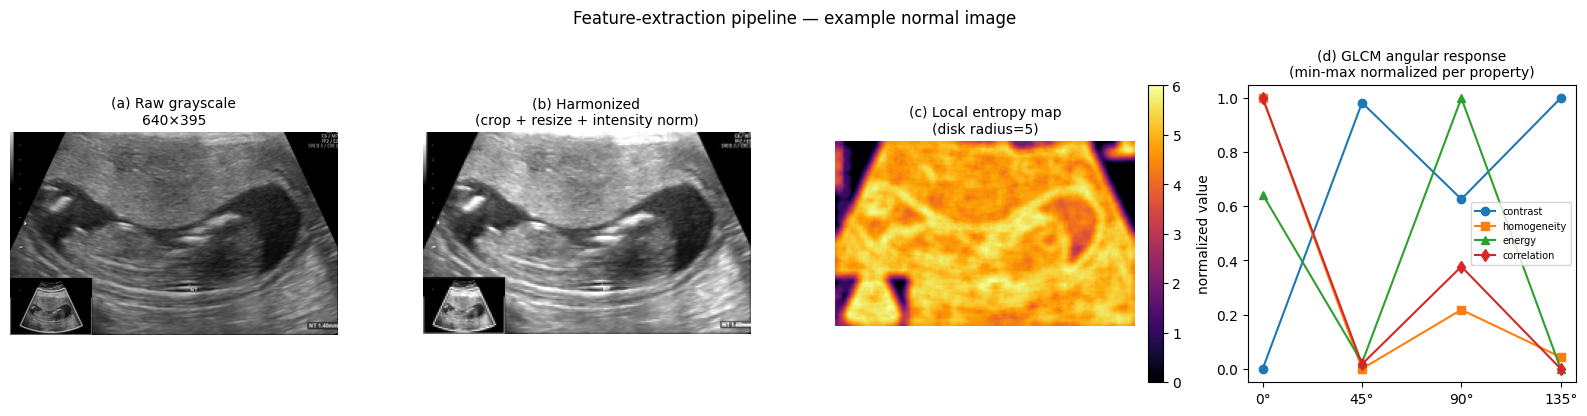


Exact feature values — Normal_0321.jpg (normal):
                               raw  harmonized_v3
mean                       78.7897       118.3928
std                        43.3804        63.7473
variance                 1881.8590      4063.7144
skewness                   -0.2871        -0.3648
kurtosis                   -0.4773        -0.5580
entropy                     6.8863         6.8388
energy_mean_sq           8089.6759     18080.5753
min                         0.0000         0.0000
max                       238.0000       255.0000
p10                         0.0000         1.0000
p25                        50.0000        76.0000
p75                       109.0000       164.0000
p90                       127.0000       190.0000
glcm_contrast_mean          7.3735        15.6608
glcm_contrast_std           2.7624         6.8780
glcm_dissimilarity_mean     1.5395         2.3660
glcm_dissimilarity_std      0.3970         0.6704
glcm_homogeneity_mean       0.5468         0.4484


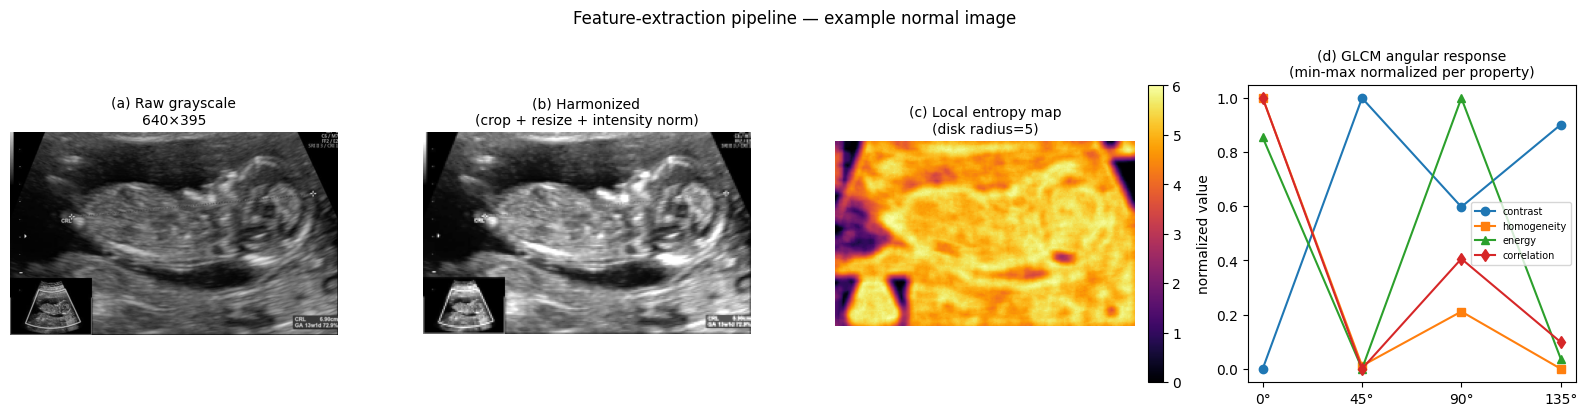


Exact feature values — Normal_0085.jpg (normal):
                               raw  harmonized_v3
mean                       68.0932       102.7841
std                        43.1233        63.4033
variance                 1859.6168      4019.9827
skewness                    0.1662         0.0437
kurtosis                   -0.4664        -0.7430
entropy                     7.1289         7.0734
energy_mean_sq           6496.3024     14584.5599
min                         0.0000         0.0000
max                       237.0000       255.0000
p10                         4.0000         7.0000
p25                        35.0000        54.0000
p75                        99.0000       148.0000
p90                       122.0000       182.0000
glcm_contrast_mean          7.8355        17.4066
glcm_contrast_std           3.0081         8.1765
glcm_dissimilarity_mean     1.6417         2.6099
glcm_dissimilarity_std      0.4525         0.7863
glcm_homogeneity_mean       0.5281         0.4206


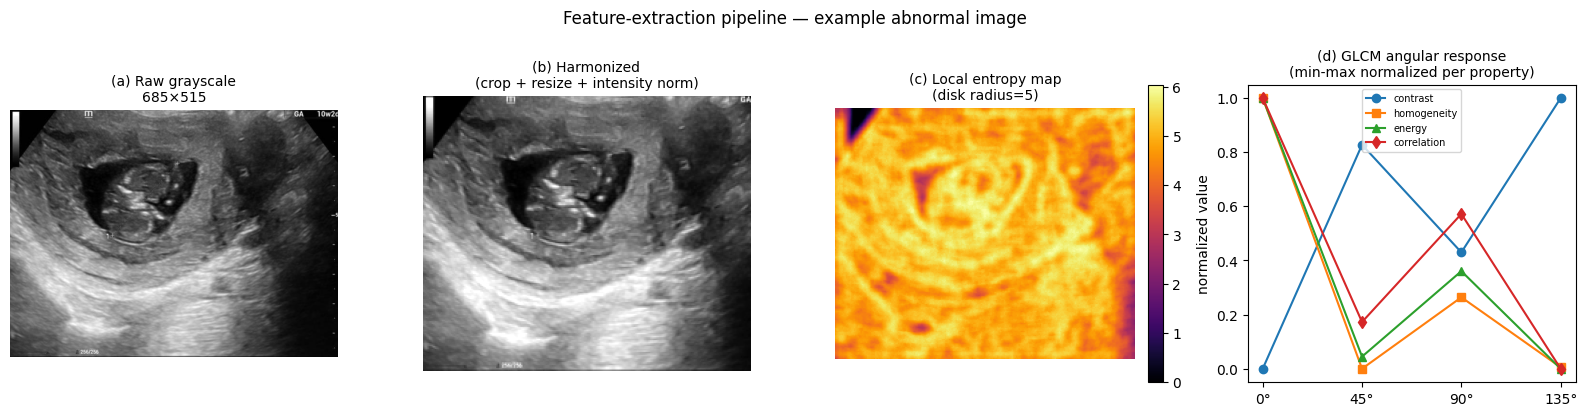


Exact feature values — Abnormal_0020.jpg (abnormal):
                                raw  harmonized_v3
mean                        94.0242       114.9152
std                         61.2041        65.5321
variance                  3745.9478      4294.4604
skewness                     0.3668         0.2922
kurtosis                    -0.8357        -0.8459
entropy                      7.7493         7.7134
energy_mean_sq           12586.5045     17499.9696
min                          0.0000         0.0000
max                        255.0000       255.0000
p10                         14.0000        30.0000
p25                         45.0000        65.0000
p75                        139.0000       165.0000
p90                        186.0000       213.0000
glcm_contrast_mean           6.8466         7.7452
glcm_contrast_std            2.6758         3.4677
glcm_dissimilarity_mean      1.5549         1.7285
glcm_dissimilarity_std       0.3825         0.4804
glcm_homogeneity_mean       

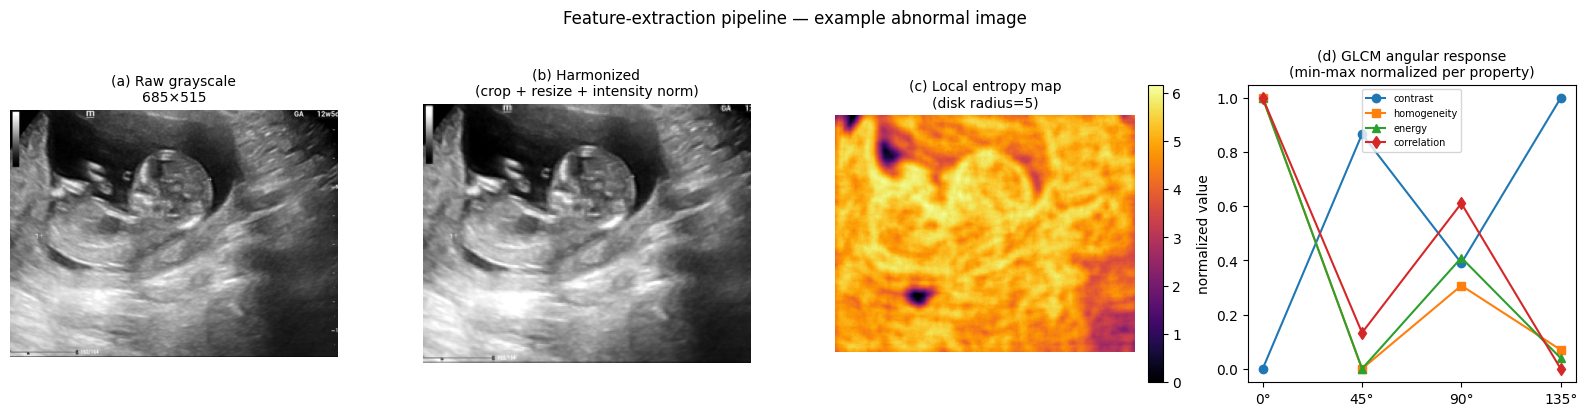


Exact feature values — Abnormal_0205.jpg (abnormal):
                                raw  harmonized_v3
mean                       108.5711       119.5541
std                         59.5279        65.4600
variance                  3543.5665      4285.0145
skewness                     0.1540         0.0768
kurtosis                    -0.9134        -0.9188
entropy                      7.8210         7.7409
energy_mean_sq           15331.2524     18578.1856
min                          0.0000         0.0000
max                        255.0000       255.0000
p10                         28.0000        28.0000
p25                         59.0000        67.0000
p75                        154.0000       170.0000
p90                        191.0000       210.0000
glcm_contrast_mean           6.8274         7.9753
glcm_contrast_std            2.9730         3.9097
glcm_dissimilarity_mean      1.4792         1.6609
glcm_dissimilarity_std       0.4213         0.5075
glcm_homogeneity_mean       

In [37]:
# =====================================================================
# Section 28 — Intermediate feature-extraction figure (for manuscript Methods)
# =====================================================================
# Paste as a NEW cell after Section 27b (cell 64). Reuses variables already
# defined in your notebook: train_samples, test_samples, CLASS_NAMES, IMG_SIZE,
# FIG_DIR, auto_crop_scan_region, aspect_preserving_resize, normalize_intensity,
# graycomatrix, graycoprops, shannon_entropy, cv2, np, pd, plt, random, SEED.
#
# Produces, per example image:
#   (a) raw grayscale image
#   (b) harmonized image (crop + aspect-preserving resize + intensity norm — v3 pipeline)
#   (c) local entropy map (texture heterogeneity, visualised spatially)
#   (d) GLCM angular response plot (contrast/homogeneity/energy/correlation vs angle)
# plus a printed table of that image's actual extracted feature values, so the
# figure caption can quote exact numbers instead of "representative example."
#
# This is the figure reviewers expect when a paper claims "radiomic/texture
# features were extracted" — it shows the extraction is real and inspectable,
# not a black box.

from skimage.filters.rank import entropy as local_entropy_filter
from skimage.morphology import disk
from skimage.feature import graycomatrix, graycoprops

N_EXAMPLES_PER_CLASS = 2  # keep the figure readable; increase for supplementary material

rng = random.Random(SEED)


def harmonize_image_v3_local(image_path: str) -> np.ndarray:
    """Same as harmonize_image_v3 in Section 25 — re-declared here so this cell
    is runnable standalone if pasted into a fresh kernel session."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(image_path)
    img = auto_crop_scan_region(img)
    img = aspect_preserving_resize(img, IMG_SIZE)
    img = normalize_intensity(img)
    return img


def glcm_angular_profile(img: np.ndarray, distance: int = 1):
    """Returns contrast/homogeneity/energy/correlation at 0/45/90/135 degrees,
    for the angular-response subplot."""
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(
        img, distances=[distance], angles=angles, levels=256,
        symmetric=True, normed=True,
    )
    props = {}
    for prop in ("contrast", "homogeneity", "energy", "correlation"):
        props[prop] = graycoprops(glcm, prop)[0]  # one value per angle
    return angles, props


def make_intermediate_feature_figure(image_path: str, label_name: str, save_path):
    raw = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    harmonized = harmonize_image_v3_local(image_path)
    ent_map = local_entropy_filter(harmonized, disk(5))
    angles, glcm_props = glcm_angular_profile(harmonized)
    angle_labels = ["0°", "45°", "90°", "135°"]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))

    axes[0].imshow(raw, cmap="gray")
    axes[0].set_title(f"(a) Raw grayscale\n{raw.shape[1]}×{raw.shape[0]}", fontsize=10)
    axes[0].axis("off")

    axes[1].imshow(harmonized, cmap="gray")
    axes[1].set_title(f"(b) Harmonized\n(crop + resize + intensity norm)", fontsize=10)
    axes[1].axis("off")

    im2 = axes[2].imshow(ent_map, cmap="inferno")
    axes[2].set_title("(c) Local entropy map\n(disk radius=5)", fontsize=10)
    axes[2].axis("off")
    fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    for prop, marker in zip(("contrast", "homogeneity", "energy", "correlation"),
                             ("o", "s", "^", "d")):
        vals = glcm_props[prop]
        vals_norm = (vals - np.min(vals)) / (np.ptp(vals) + 1e-9)  # normalize for shared axis
        axes[3].plot(angle_labels, vals_norm, marker=marker, label=prop)
    axes[3].set_title("(d) GLCM angular response\n(min-max normalized per property)", fontsize=10)
    axes[3].legend(fontsize=7, loc="best")
    axes[3].set_ylabel("normalized value")

    fig.suptitle(f"Feature-extraction pipeline — example {label_name} image", fontsize=12)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    # Print the exact scalar feature values for this image, for the figure caption
    feats_raw = extract_radiomic_features(image_path)          # from Section 4
    # NOTE: if your Section 25 cell named the v3 feature-extraction function
    # differently, swap the call below to match it — it should apply
    # harmonize_image_v3() then compute the same 25 features as Section 4.
    try:
        feats_harm = extract_radiomic_features_harmonized_v3(image_path)
    except NameError:
        def _extract_from_array(img):
            f = {}
            f["mean"], f["std"], f["variance"] = float(np.mean(img)), float(np.std(img)), float(np.var(img))
            f["skewness"] = float(pd.Series(img.ravel()).skew())
            f["kurtosis"] = float(pd.Series(img.ravel()).kurtosis())
            f["entropy"] = float(shannon_entropy(img))
            f["energy_mean_sq"] = float(np.mean(img.astype(np.float64) ** 2))
            f["min"], f["max"] = float(np.min(img)), float(np.max(img))
            p10, p25, p75, p90 = np.percentile(img, [10, 25, 75, 90])
            f["p10"], f["p25"], f["p75"], f["p90"] = map(float, (p10, p25, p75, p90))
            return f
        feats_harm = _extract_from_array(harmonized)
    comparison = pd.DataFrame({"raw": feats_raw, "harmonized_v3": feats_harm}).round(4)
    print(f"\nExact feature values — {os.path.basename(image_path)} ({label_name}):")
    print(comparison.to_string())
    return comparison


# ---- Select examples and generate one figure per example ----
all_labeled = [(p, CLASS_NAMES[l]) for p, l in (train_samples + test_samples)]
examples = []
for cname in CLASS_NAMES:
    pool = [p for p, l in all_labeled if l == cname]
    examples += [(p, cname) for p in rng.sample(pool, min(N_EXAMPLES_PER_CLASS, len(pool)))]

feature_value_tables = {}
for path, cname in examples:
    out_path = FIG_DIR / f"intermediate_features_{cname}_{Path(path).stem}.png"
    feature_value_tables[path] = make_intermediate_feature_figure(path, cname, out_path)

print(f"\nSaved {len(examples)} intermediate-feature figures to {FIG_DIR}")
print("Use one representative normal + one representative abnormal panel as the")
print("manuscript Methods figure; keep the rest as supplementary material.")